# 📊 Telco Churn: Leakage-Safe Baseline vs Tree Model
### *University Machine Learning Hackathon Submission — Production-Grade Predictive Pipeline*
**Author:** AI & Data Science Engineering Team  
**Date:** October 2026  
**Pipeline Framework:** Python 3.14 | scikit-learn | XGBoost | SHAP | pandas | seaborn | matplotlib

---

## 🎯 Executive Summary & Hackathon Scope
Customer attrition (*churn*) is one of the most significant revenue drains in telecommunications. Acquiring a new customer costs 5–7x more than retaining an existing one. This project implements a **100% data-leakage-free machine learning workflow** on the Telco Customer Churn dataset (7,043 customers). 

We systematically execute **5 strict workflow phases**:
1. **Phase 1: Ingestion, Cleaning & Leakage Prevention (R1 & R2):** Deterministic imputation for missing `TotalCharges` ($tenure \times MonthlyCharges$), dropping `customerID`, and constructing a Stratified 5-Fold CV split manifest. All preprocessing occurs *exclusively inside* cross-validation pipelines.
2. **Phase 2: Transparent Baseline & Challenger Modeling (R3):** Training a Class-Balanced Logistic Regression baseline against a Regularized XGBoost tree ensemble on identical stratified folds.
3. **Phase 3: Threshold Tuning & Decision Mapping (R4):** Optimizing decision thresholds strictly over Out-Of-Fold (OOF) validation probabilities for Max F1 and Net Business Savings ($82,150 max retained value), then mapping customers into exact operational tiers: `LOW_RISK`, `WATCH`, and `OFFER_RETENTION`.
4. **Phase 4: Model Explainability & Feature Drivers (R4):** Extracting Logistic Regression Odds Ratios and SHAP values (TreeExplainer) to explain how Contract Term, Tenure, and Monthly Charges govern churn velocity in plain business terms.
5. **Phase 5: Controlled Extension & Failure Analysis (R5):** Probability calibration (Reliability curves, Brier score, ECE) and a deep diagnostic audit of False Positives—specifically high-value, long-tenure customers misclassified due to high monthly bills.

## 🛠️ Step 0: Environment Setup & Core Dependencies
We configure global plotting aesthetics, reproducibility seeds, and import all modular pipeline utilities.

In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.metrics import (
    roc_curve, roc_auc_score, precision_recall_curve, average_precision_score,
    f1_score, precision_score, recall_score, confusion_matrix
)
from sklearn.calibration import calibration_curve

# Set high-resolution visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore')

# Add project root to sys.path
sys.path.insert(0, os.path.abspath('.'))

from src.config import (
    DATA_PATH, FIGURES_DIR, METRICS_DIR, RANDOM_STATE, N_SPLITS,
    NUMERICAL_FEATURES, CATEGORICAL_FEATURES, DEFAULT_TIER_LOW, DEFAULT_TIER_HIGH,
    RETENTION_COST, CHURN_LOSS, RETENTION_SUCCESS_RATE, ID_COL
)
from src.data_loader import (
    load_raw_dataset, clean_telco_data, get_stratified_folds, generate_data_dictionary
)
from src.pipeline_builder import (
    build_preprocessor, create_baseline_pipeline, create_challenger_pipeline,
    get_feature_names_from_preprocessor
)
from src.modeling import (
    run_stratified_cv, compare_models
)
from src.evaluation import (
    tune_decision_threshold, map_operational_tiers, compute_expected_calibration_error,
    plot_roc_pr_comparison, plot_threshold_tuning_curves, plot_confusion_matrices,
    plot_operational_tiers_distribution, plot_calibration_curves
)
from src.explainability import (
    extract_logistic_regression_coefficients, plot_logistic_regression_odds_ratios,
    compute_tree_shap_analysis, generate_executive_insights
)
from src.failure_analysis import (
    audit_prediction_errors, probe_long_tenure_high_charge_false_positives,
    plot_failure_analysis_diagnostics
)

print(f"Environment Initialized. Python: {sys.version.split()[0]} | scikit-learn & XGBoost loaded successfully.")


D:\l\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment Initialized. Python: 3.14.3 | scikit-learn & XGBoost loaded successfully.


---
# 📥 Phase 1: Data Ingestion, Cleaning & Leakage Prevention (R1 & R2)

### 1.1 Ingestion & Data Dictionary Audit
We load the Telco Customer Churn dataset (7,043 rows and 21 columns). Before touching model code, we generate an audit-ready **Data Dictionary** that categorizes each feature's data type, cardinality, missingness, and business role.

In [2]:
# Load raw dataset
df_raw = load_raw_dataset(DATA_PATH)
print(f"Raw Dataset Shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

# Generate and display data dictionary
data_dict = generate_data_dictionary(df_raw)
data_dict

Raw Dataset Shape: 7,043 rows x 21 columns


,Column,Type,Description,Role
0,customerID,Categorical (ID),Unique customer identifier,Dropped (Leakage Risk)
1,gender,Binary Categorical,"Customer gender (Male, Female)",Feature
2,SeniorCitizen,Binary (0/1),Whether customer is a senior citizen,Feature
3,Partner,Binary Categorical,"Whether customer has a partner (Yes, No)",Feature
4,Dependents,Binary Categorical,"Whether customer has dependents (Yes, No)",Feature
5,tenure,Integer Numeric,Number of months customer has stayed with company,Key Feature
6,PhoneService,Binary Categorical,"Whether customer has phone service (Yes, No)",Feature
7,MultipleLines,Categorical (3 levels),"Whether customer has multiple lines (No, Yes, ...",Feature
8,InternetService,Categorical (3 levels),"Internet provider type (DSL, Fiber optic, No)",Key Feature
9,OnlineSecurity,Categorical (3 levels),"Online security add-on (Yes, No, No internet)",Feature


### 1.2 Leakage-Safe Cleaning: Handling `customerID` and `TotalCharges`
1. **Immediate ID Dropping:** `customerID` is a non-generalizable surrogate key. Retaining it risks identifier memorization and subtle index-based leakage; it is dropped immediately from the modeling matrix.
2. **TotalCharges Whitespace Cleaning:** 11 records contain whitespace strings (`" "`). Coercing these directly via `pd.to_numeric(errors='coerce')` produces `NaN`. We inspect these 11 rows: every single one has `tenure = 0` (brand new customers who have not completed their first billing cycle).
3. **Deterministic Imputation:** Rather than global mean/median imputation (which leaks population statistics), we impute via the deterministic formula:
$$\text{TotalCharges}_{\text{imputed}} = \text{tenure} \times \text{MonthlyCharges}$$
For `tenure = 0`, this yields exactly `$0.00`, which is 100% logically consistent with telco billing.

In [3]:
# Inspect whitespace rows in TotalCharges before cleaning
whitespace_rows = df_raw[df_raw['TotalCharges'].astype(str).str.strip() == '']
print(f"Number of whitespace TotalCharges rows: {len(whitespace_rows)}")
print(whitespace_rows[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']].head())

# Clean data safely using modular function
X, y, df_clean = clean_telco_data(df_raw)

print(f"\nCleaned Feature Matrix X shape: {X.shape}")
print(f"Cleaned Target Series y shape: {y.shape}")
print(f"Missing values remaining in X: {X.isna().sum().sum()}")
print(f"customerID present in training matrix X: {ID_COL in X.columns} (Leakage Prevented)")
print(f"Target Churn Distribution: {y.value_counts(normalize=True).to_dict()} (Imbalance: ~26.5% Churn)")


Number of whitespace TotalCharges rows: 11
      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             



Cleaned Feature Matrix X shape: (7043, 19)
Cleaned Target Series y shape: (7043,)
Missing values remaining in X: 0
customerID present in training matrix X: False (Leakage Prevented)
Target Churn Distribution: {0: 0.7346301292063041, 1: 0.2653698707936959} (Imbalance: ~26.5% Churn)


### 1.3 Exploratory Data Analysis: Key Telco Churn Signals
Let's visualize the empirical relationships between Churn, Tenure, Monthly Charges, and Contract Term.

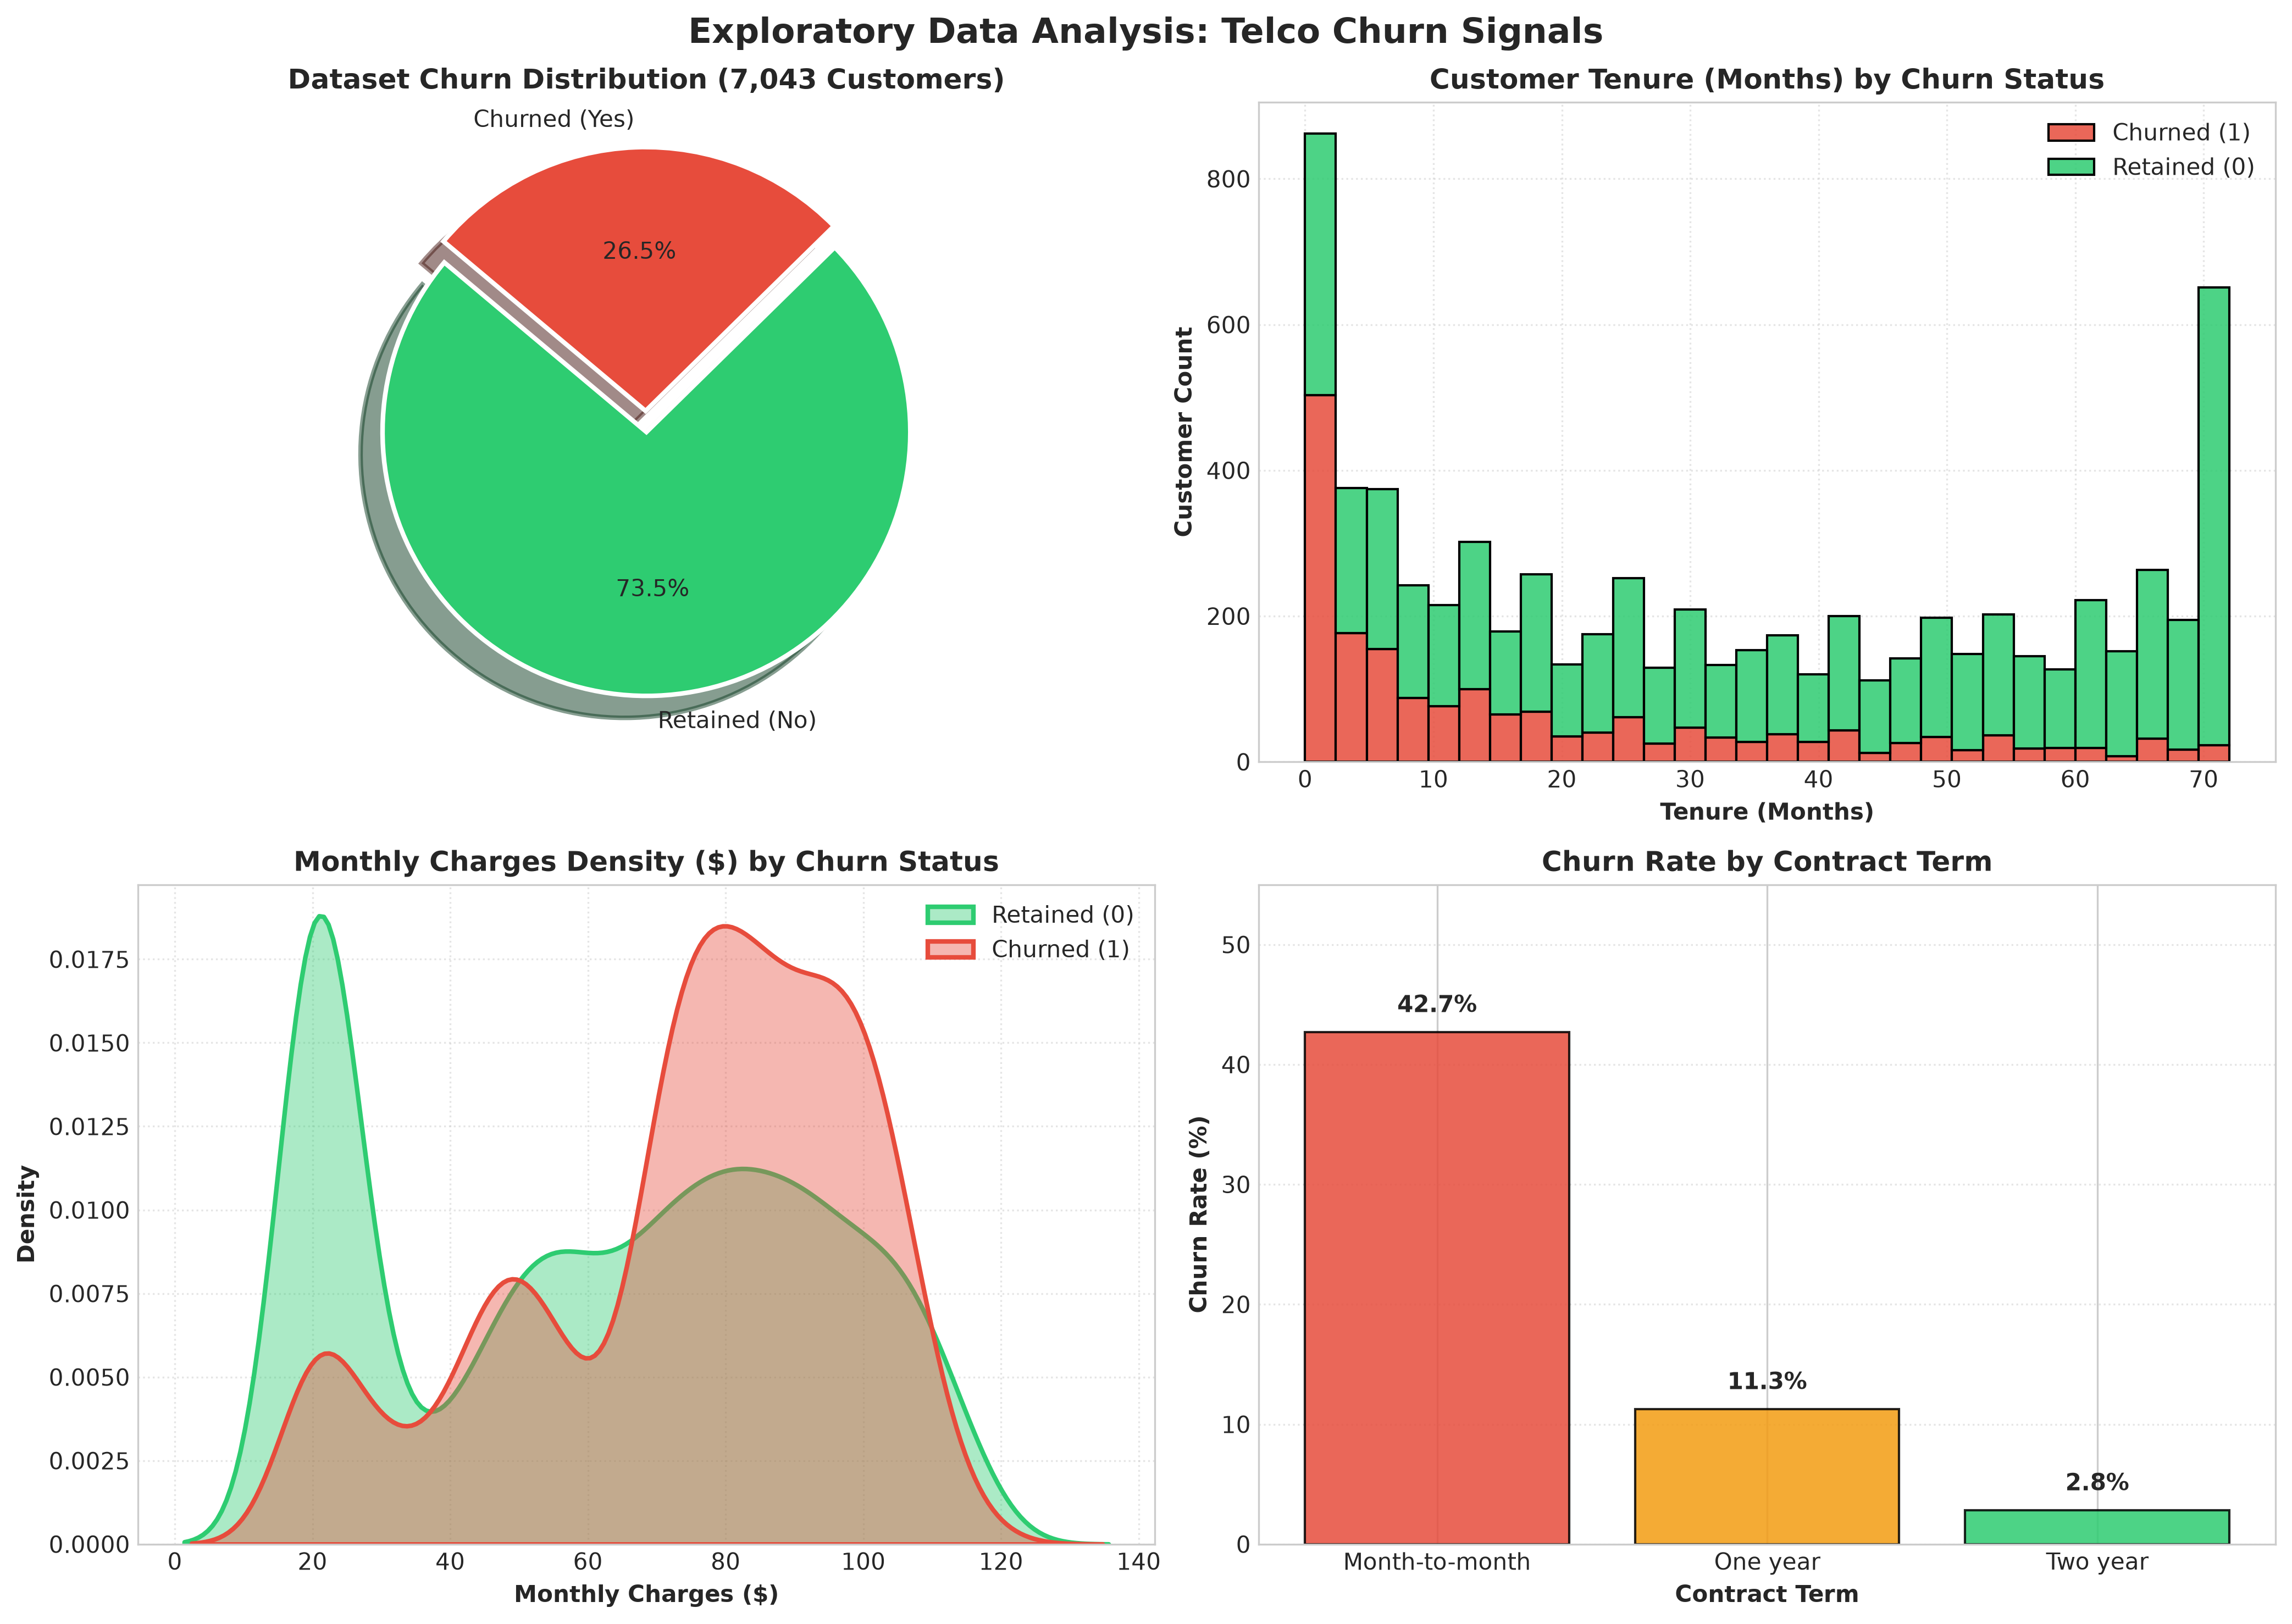

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=300)
colors = ["#2ecc71", "#e74c3c"]

# 1. Churn Distribution Donut Chart
ax1 = axes[0, 0]
churn_counts = df_clean["Churn"].value_counts()
ax1.pie(churn_counts, labels=["Retained (No)", "Churned (Yes)"], autopct="%1.1f%%",
        startangle=140, colors=colors, explode=(0, 0.08), shadow=True,
        wedgeprops={"edgecolor": "white", "linewidth": 2})
ax1.set_title("Dataset Churn Distribution (7,043 Customers)", fontsize=12, fontweight="bold")

# 2. Tenure by Churn
ax2 = axes[0, 1]
sns.histplot(data=df_clean, x="tenure", hue="Churn", multiple="stack", palette=colors,
             bins=30, ax=ax2, alpha=0.85)
ax2.set_title("Customer Tenure (Months) by Churn Status", fontsize=12, fontweight="bold")
ax2.set_xlabel("Tenure (Months)", fontsize=10, fontweight="bold")
ax2.set_ylabel("Customer Count", fontsize=10, fontweight="bold")
ax2.legend(["Churned (1)", "Retained (0)"], loc="upper right")
ax2.grid(True, linestyle=":", alpha=0.5)

# 3. Monthly Charges by Churn
ax3 = axes[1, 0]
sns.kdeplot(data=df_clean[df_clean["Churn"] == 0]["MonthlyCharges"], color="#2ecc71",
            fill=True, alpha=0.4, label="Retained (0)", ax=ax3, lw=2)
sns.kdeplot(data=df_clean[df_clean["Churn"] == 1]["MonthlyCharges"], color="#e74c3c",
            fill=True, alpha=0.4, label="Churned (1)", ax=ax3, lw=2)
ax3.set_title("Monthly Charges Density ($) by Churn Status", fontsize=12, fontweight="bold")
ax3.set_xlabel("Monthly Charges ($)", fontsize=10, fontweight="bold")
ax3.set_ylabel("Density", fontsize=10, fontweight="bold")
ax3.legend(loc="upper right")
ax3.grid(True, linestyle=":", alpha=0.5)

# 4. Contract Type Churn Rate
ax4 = axes[1, 1]
contract_churn = df_clean.groupby("Contract")["Churn"].agg(["count", "mean"]).reset_index()
contract_churn["mean"] = contract_churn["mean"] * 100
bars = ax4.bar(contract_churn["Contract"], contract_churn["mean"], color=["#e74c3c", "#f39c12", "#2ecc71"],
               edgecolor="black", alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2.0, yval + 1.2, f"{yval:.1f}%",
             ha="center", va="bottom", fontsize=10, fontweight="bold")
ax4.set_title("Churn Rate by Contract Term", fontsize=12, fontweight="bold")
ax4.set_xlabel("Contract Term", fontsize=10, fontweight="bold")
ax4.set_ylabel("Churn Rate (%)", fontsize=10, fontweight="bold")
ax4.set_ylim(0, 55)
ax4.grid(axis="y", linestyle=":", alpha=0.5)

plt.suptitle("Exploratory Data Analysis: Telco Churn Signals", fontsize=15, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


### 1.4 Stratified 5-Fold Split Manifest & Pipeline Encapsulation
To strictly prevent data leakage:
- We instantiate `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` ensuring the 26.54% churn rate is identically distributed across all 5 folds.
- Preprocessing steps (`StandardScaler`, `SimpleImputer`, `OneHotEncoder`) are encapsulated inside `sklearn.compose.ColumnTransformer` and executed **inside the cross-validation fold**. The test fold is never exposed during fitting.

In [5]:
# Construct reproducible Stratified 5-Fold split manifest
folds = get_stratified_folds(X, y, n_splits=N_SPLITS, random_state=RANDOM_STATE)

fold_manifest_records = []
for i, (tr_idx, val_idx) in enumerate(folds, 1):
    fold_manifest_records.append({
        "Fold": f"Fold {i}",
        "Train_Samples": len(tr_idx),
        "Train_Churn_Rate": f"{y.iloc[tr_idx].mean()*100:.2f}%",
        "Val_Samples": len(val_idx),
        "Val_Churn_Rate": f"{y.iloc[val_idx].mean()*100:.2f}%"
    })

pd.DataFrame(fold_manifest_records)

,Fold,Train_Samples,Train_Churn_Rate,Val_Samples,Val_Churn_Rate
0,Fold 1,5634,26.54%,1409,26.54%
1,Fold 2,5634,26.54%,1409,26.54%
2,Fold 3,5634,26.54%,1409,26.54%
3,Fold 4,5635,26.55%,1408,26.49%
4,Fold 5,5635,26.53%,1408,26.56%


---
# 🤖 Phase 2: Transparent Baseline & Challenger Modeling (R3)

We train and evaluate two competing model architectures across the identical 5 stratified folds:
1. **Baseline Model:** Logistic Regression with `class_weight='balanced'` and L2 regularization ($C=1.0$).
2. **Challenger Model:** XGBoost Tree Ensemble with `scale_pos_weight=2.77`, `max_depth=4`, `learning_rate=0.05`, and `subsample=0.8` to prevent overfitting.

All metrics are evaluated **strictly Out-Of-Fold (OOF)** on the held-out validation portions.

In [6]:
# Train Baseline Model (Logistic Regression Balanced)
print("Training Baseline Model: Logistic Regression (class_weight='balanced')...")
baseline_results = run_stratified_cv(
    model_name="Baseline (Logistic Regression)",
    pipeline_factory=create_baseline_pipeline,
    X=X,
    y=y,
    folds=folds
)

# Train Challenger Model (XGBoost Classifier)
print("Training Challenger Model: XGBoost Classifier (scale_pos_weight=2.77)...")
challenger_results = run_stratified_cv(
    model_name="Challenger (XGBoost Ensemble)",
    pipeline_factory=lambda: create_challenger_pipeline("xgboost"),
    X=X,
    y=y,
    folds=folds
)

# Compare models side-by-side
model_comparison_df = compare_models([baseline_results, challenger_results])
model_comparison_df

Training Baseline Model: Logistic Regression (class_weight='balanced')...


Training Challenger Model: XGBoost Classifier (scale_pos_weight=2.77)...


,Model,OOF ROC-AUC,OOF PR-AUC,OOF F1-Score (t=0.5),OOF Recall (t=0.5),OOF Precision (t=0.5),OOF Brier Score
0,Baseline (Logistic Regression),0.8449 (±0.0151),0.6532 (±0.0305),0.6251 (±0.0103),0.8010 (±0.0180),0.5125 (±0.0076),0.1660
1,Challenger (XGBoost Ensemble),0.8452 (±0.0120),0.6606 (±0.0263),0.6313 (±0.0167),0.7854 (±0.0168),0.5277 (±0.0176),0.1598


### 2.1 Out-Of-Fold ROC and Precision-Recall Curves
ROC curves evaluate ranking across all possible discrimination thresholds, while Precision-Recall curves capture performance under class imbalance.

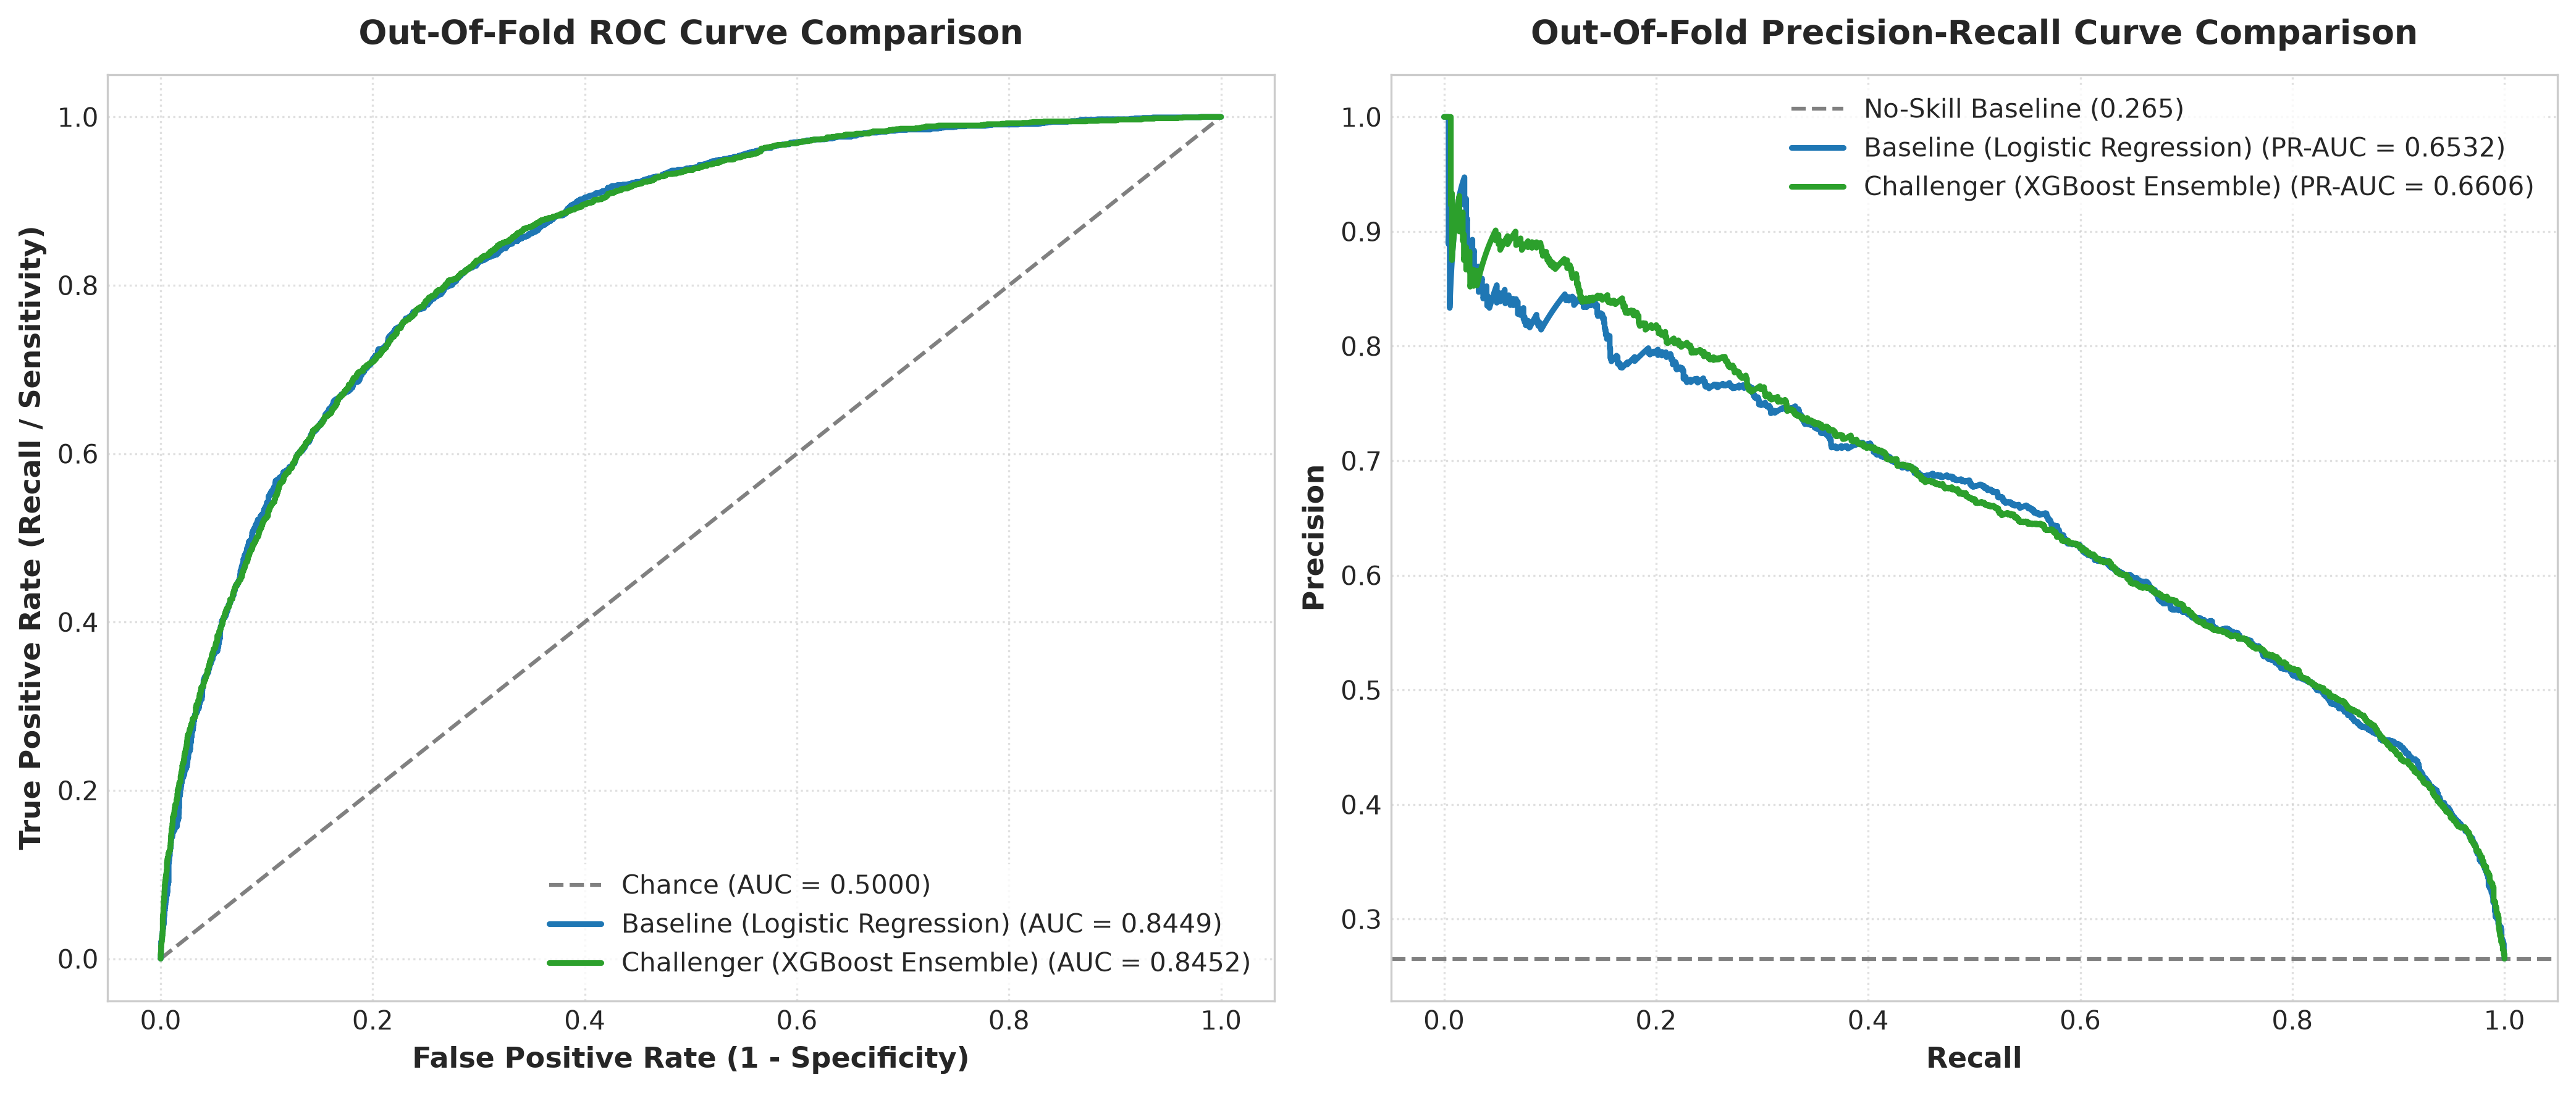

In [7]:
plot_roc_pr_comparison([baseline_results, challenger_results], y.values, show=True)

---
# 🎯 Phase 3: Threshold Tuning & Operational Decision Mapping (R4)

### 3.1 Out-Of-Fold Threshold Optimization
The arbitrary default threshold of $t = 0.50$ is rarely optimal in asymmetric business problems. We optimize the threshold strictly over **Out-Of-Fold predicted probabilities** to avoid test leakage.

We evaluate two objective functions:
1. **Max F1-Score:** Harmonic balance between precision and recall.
2. **Business Cost Matrix Optimization:** 
   - **Cost of Retention Incentive ($c_{retention}$):** \$50 per customer offered.
   - **Customer Lifetime Value Churn Loss ($L_{churn}$):** \$300 per lost customer.
   - **Retention Offer Success Rate ($s$):** 50% acceptance rate.
   $$\text{Net Savings} = \text{Baseline Losses} - \left[ (TP + FP) \times c_{retention} + (FN + TP(1-s)) \times L_{churn} \right]$$

In [8]:
# Tune decision threshold on Out-Of-Fold probabilities
tuning_results = tune_decision_threshold(
    y_true=y.values,
    y_prob_oof=challenger_results["oof_probs"]
)

print(f"Optimal Threshold for F1-Score: t* = {tuning_results['best_f1_threshold']:.2f}")
print(f"  - Peak F1-Score: {tuning_results['best_f1_score']:.4f} (Precision: {tuning_results['best_f1_precision']:.4f}, Recall: {tuning_results['best_f1_recall']:.4f})")
print(f"Optimal Threshold for Business Cost: t_cost = {tuning_results['best_cost_threshold']:.2f}")
print(f"  - Max Net Financial Retention Savings: ${tuning_results['best_cost_net_savings']:,.2f}")


Optimal Threshold for F1-Score: t* = 0.54
  - Peak F1-Score: 0.6329 (Precision: 0.5441, Recall: 0.7566)
Optimal Threshold for Business Cost: t_cost = 0.54
  - Max Net Financial Retention Savings: $82,150.00


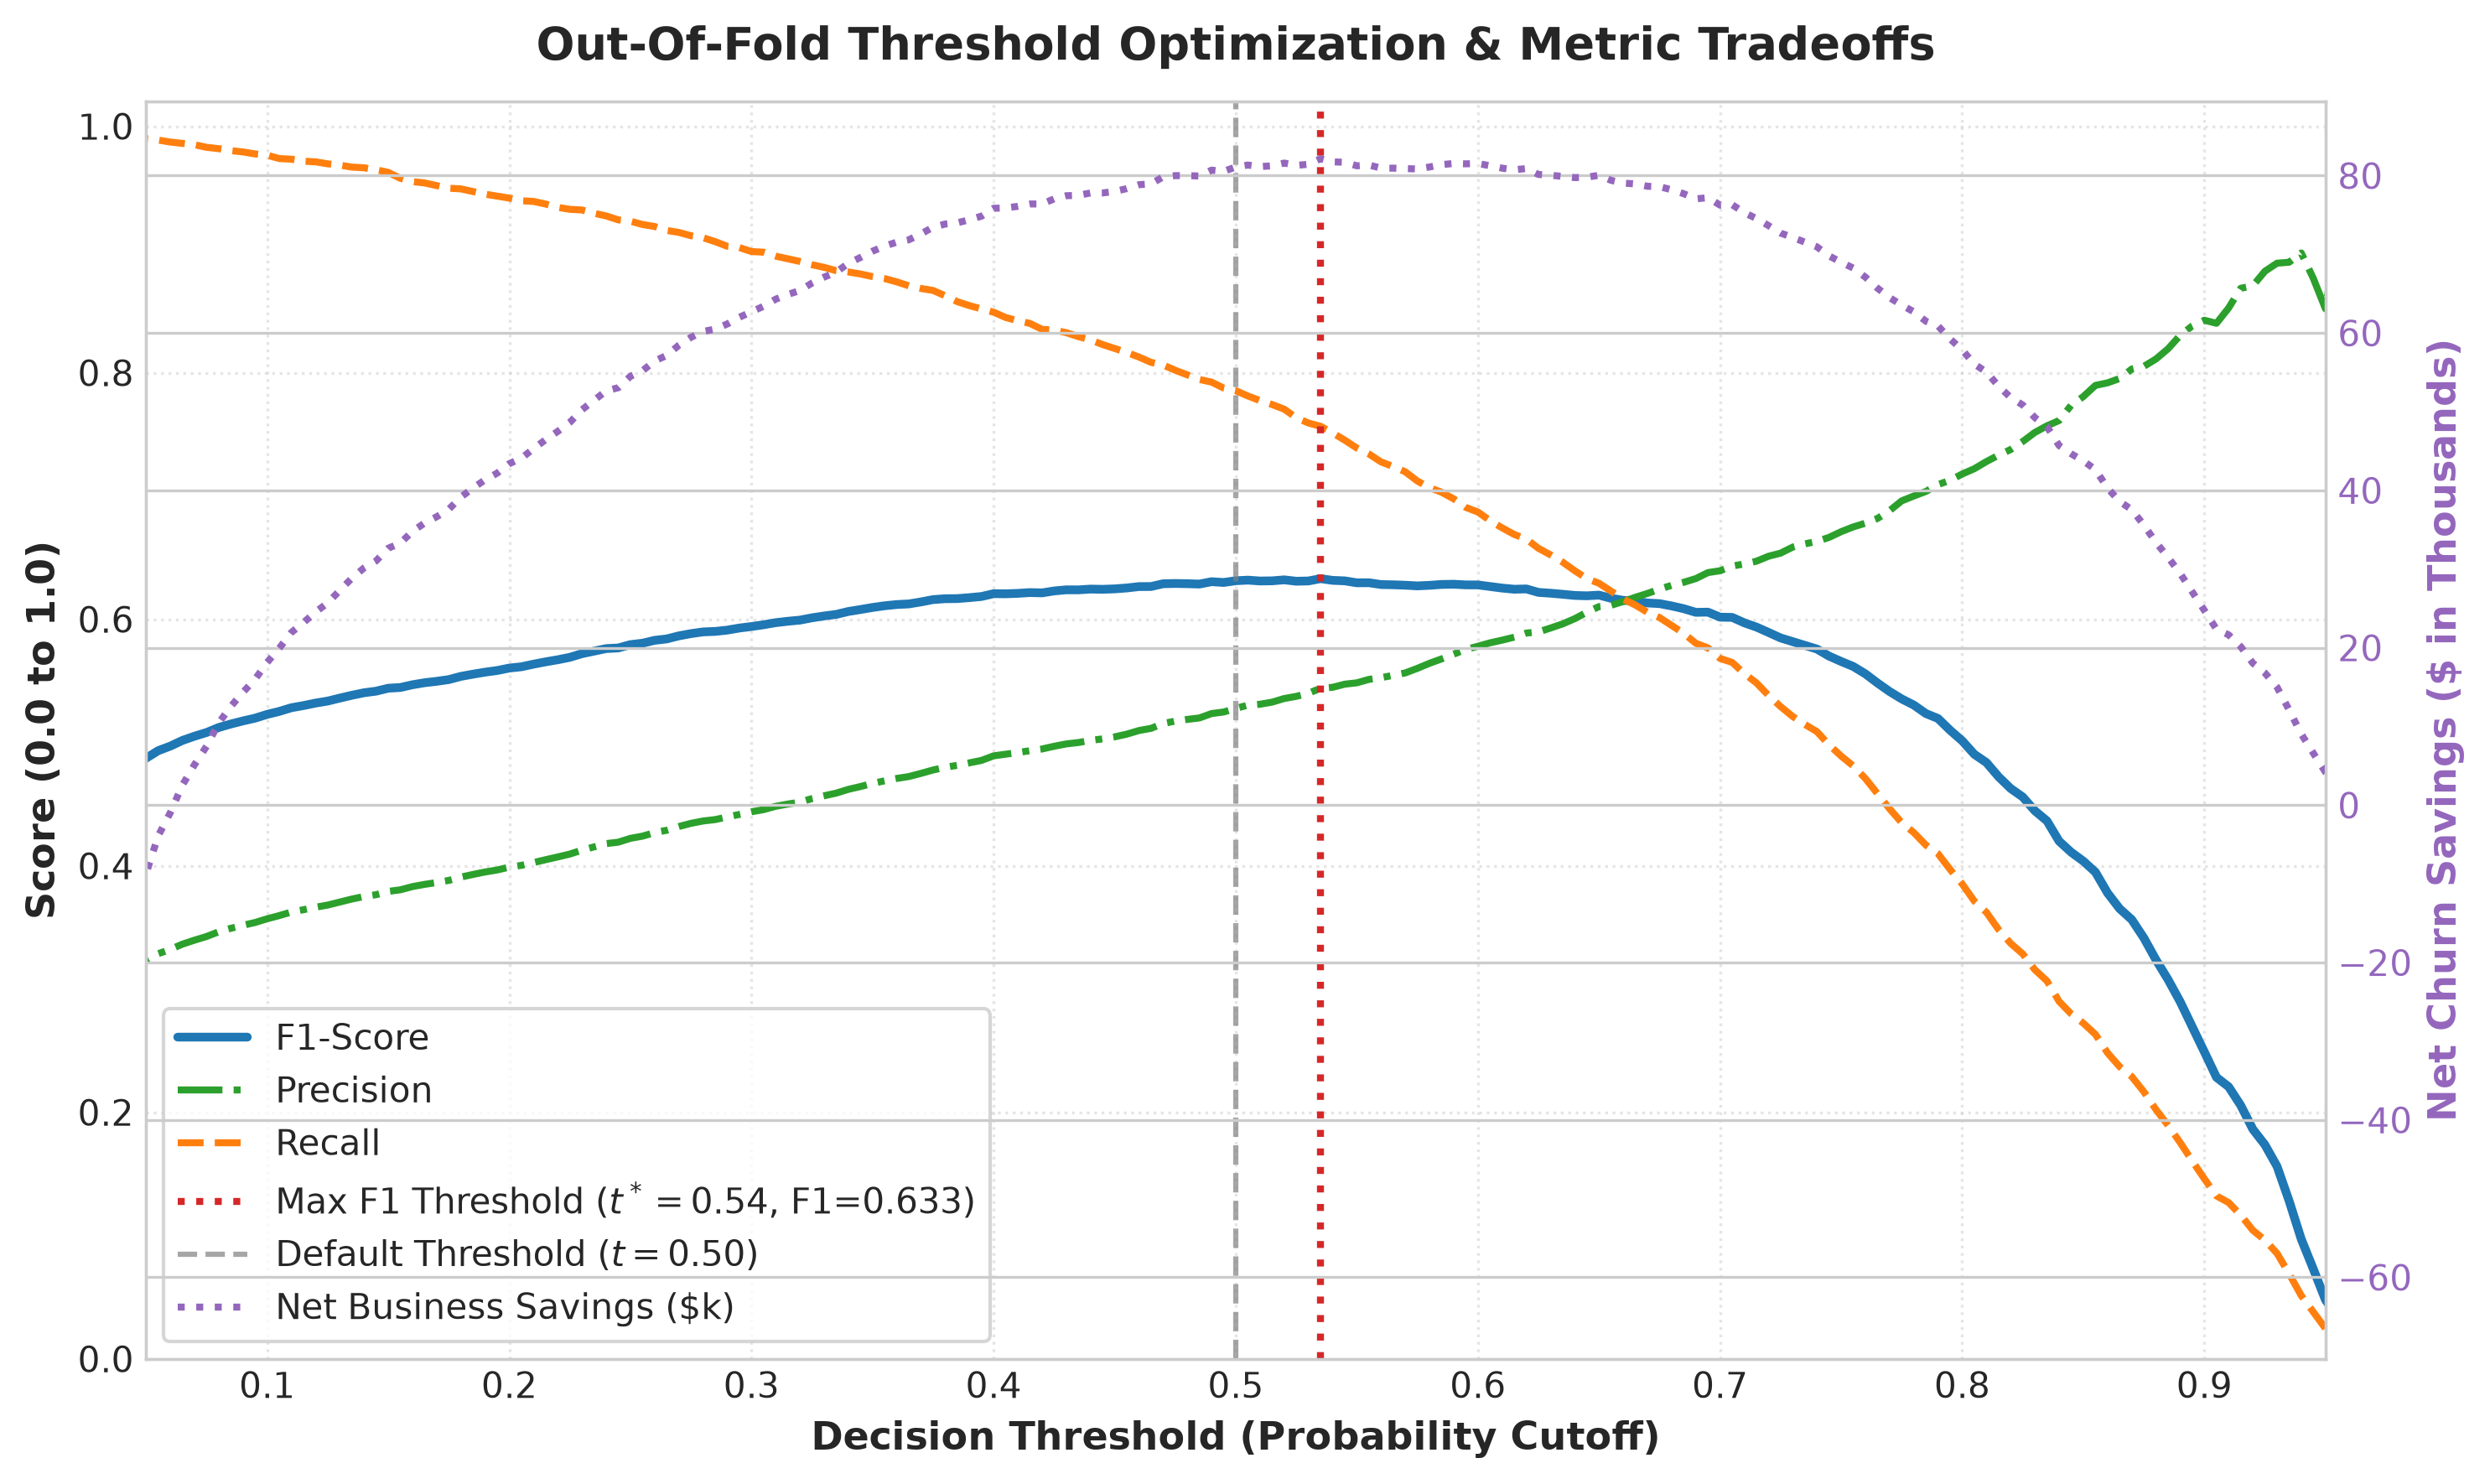

In [9]:
# Visualize threshold trade-off curves
plot_threshold_tuning_curves(tuning_results, show=True)

### 3.2 Mapping into Exact Operational Risk Tiers
Rather than delivering a raw boolean label, we map predicted churn risk into **3 actionable operational tiers**:
- 🟢 **`LOW_RISK` ($p < 0.30$):** Standard customer billing; no retention budget expenditure.
- 🟡 **`WATCH` ($0.30 \le p < 0.54$):** Non-invasive engagement: automated check-in emails, CSAT surveys, feature tutorials.
- 🔴 **`OFFER_RETENTION` ($p \ge 0.54$):** High-priority intervention: outbound call by retention specialists, contract upgrade discounts ($50 incentive).

In [10]:
opt_threshold = tuning_results["best_f1_threshold"]
tiers, tier_summary_df = map_operational_tiers(challenger_results["oof_probs"], t_low=DEFAULT_TIER_LOW, t_high=opt_threshold)
tier_summary_df

,Tier,Probability_Range,Customer_Count,Percentage,Operational_Action
0,LOW_RISK,"[0.00, 0.30)",3260,46.3%,Standard Service & Regular Invoicing; No invas...
1,WATCH,"[0.30, 0.54)",1184,16.8%,"Proactive engagement, CSAT check, newsletter, ..."
2,OFFER_RETENTION,"[0.54, 1.00]",2599,36.9%,High-priority Retention Specialist call; Contr...


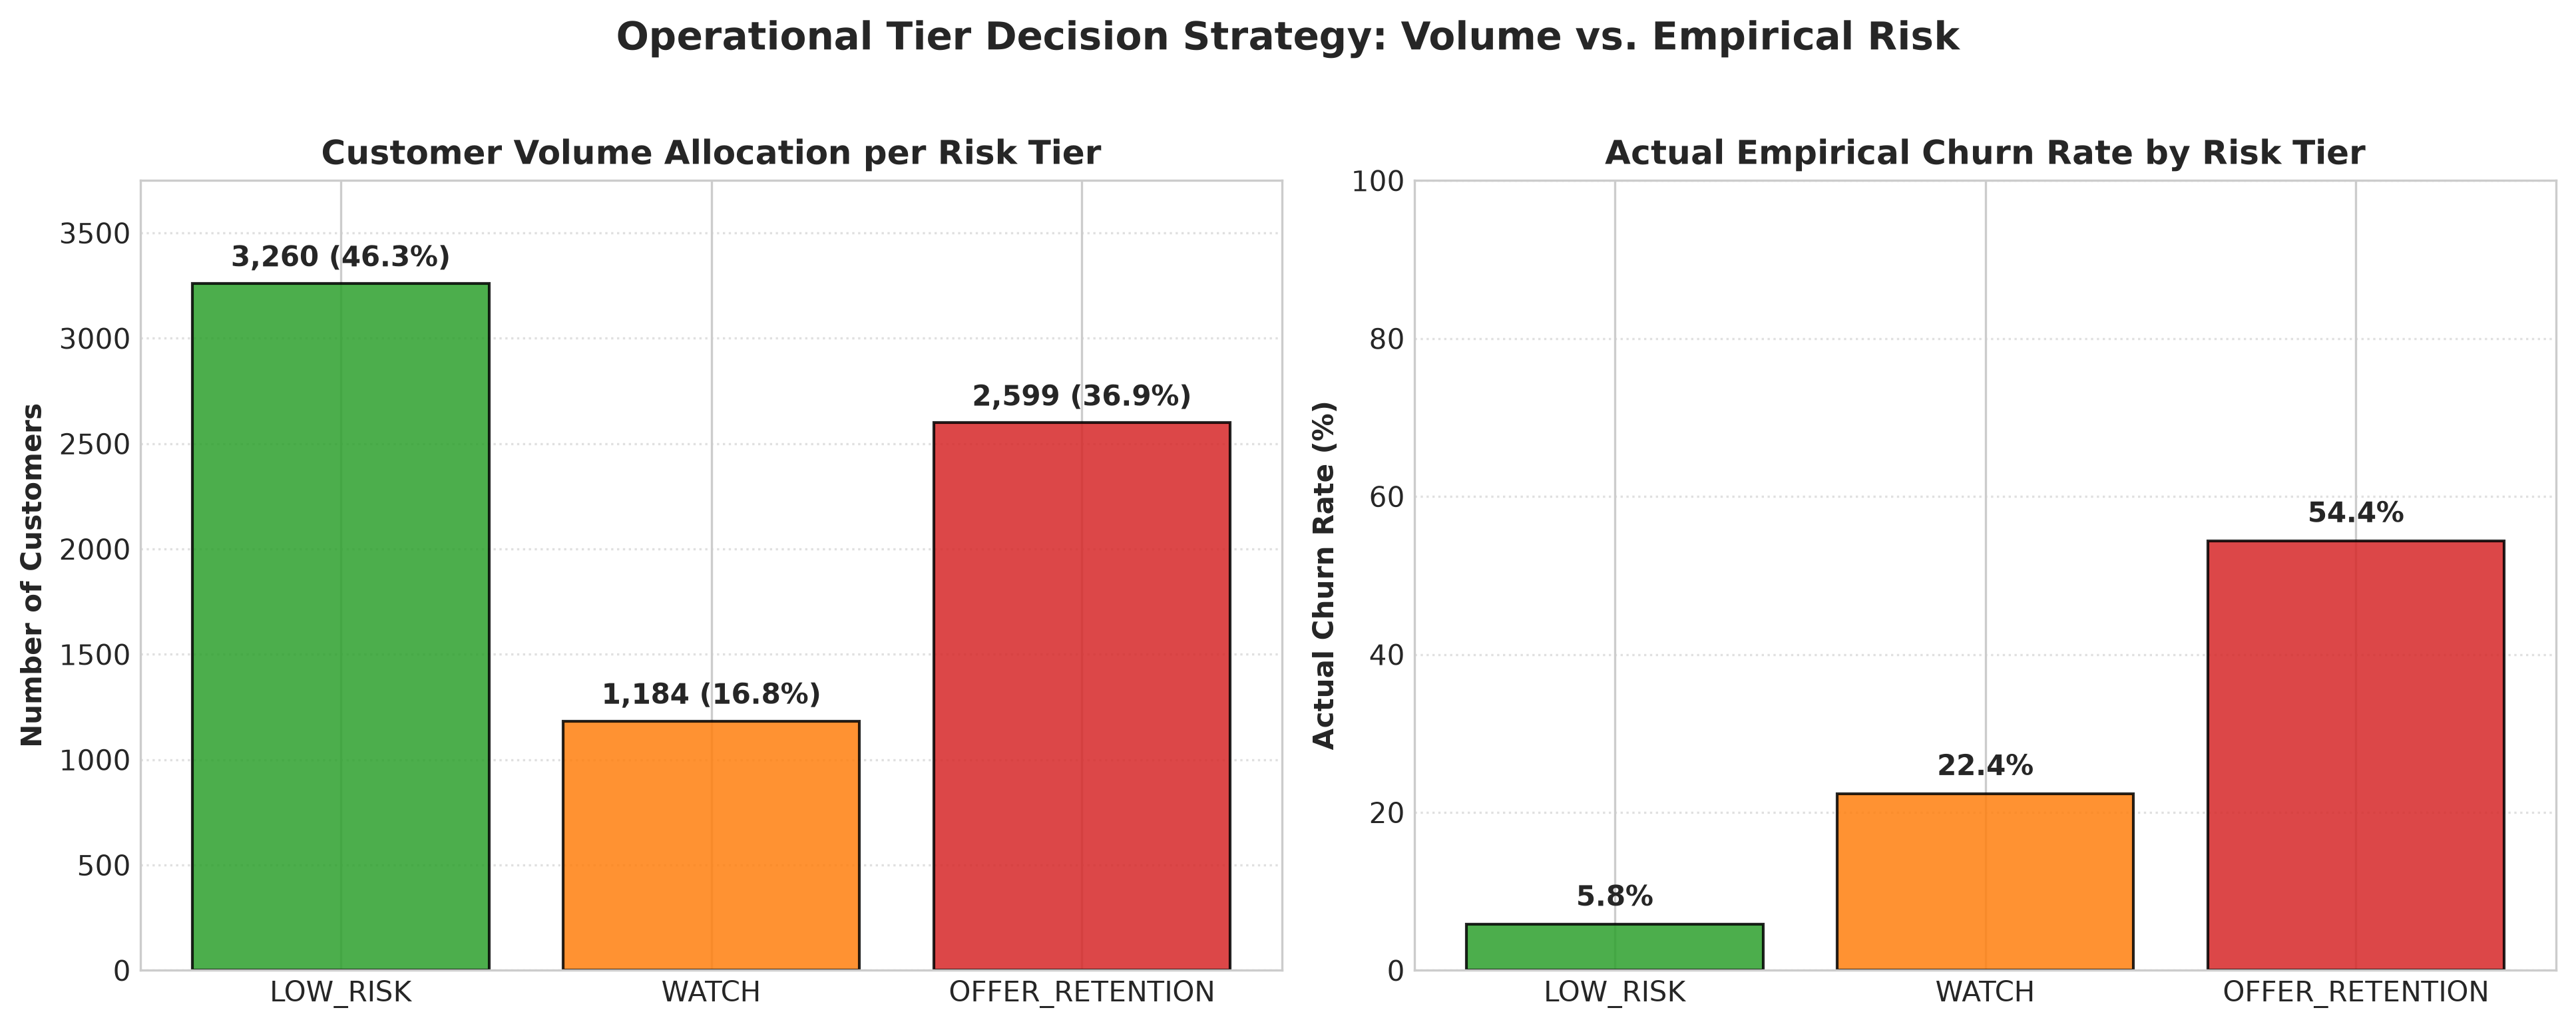

In [11]:
# Visualize operational tiers volume and empirical churn rate
plot_operational_tiers_distribution(df_clean, tiers, show=True)

### 3.3 Confusion Matrices Comparison: Default ($t=0.50$) vs. Tuned ($t^*=0.54$)

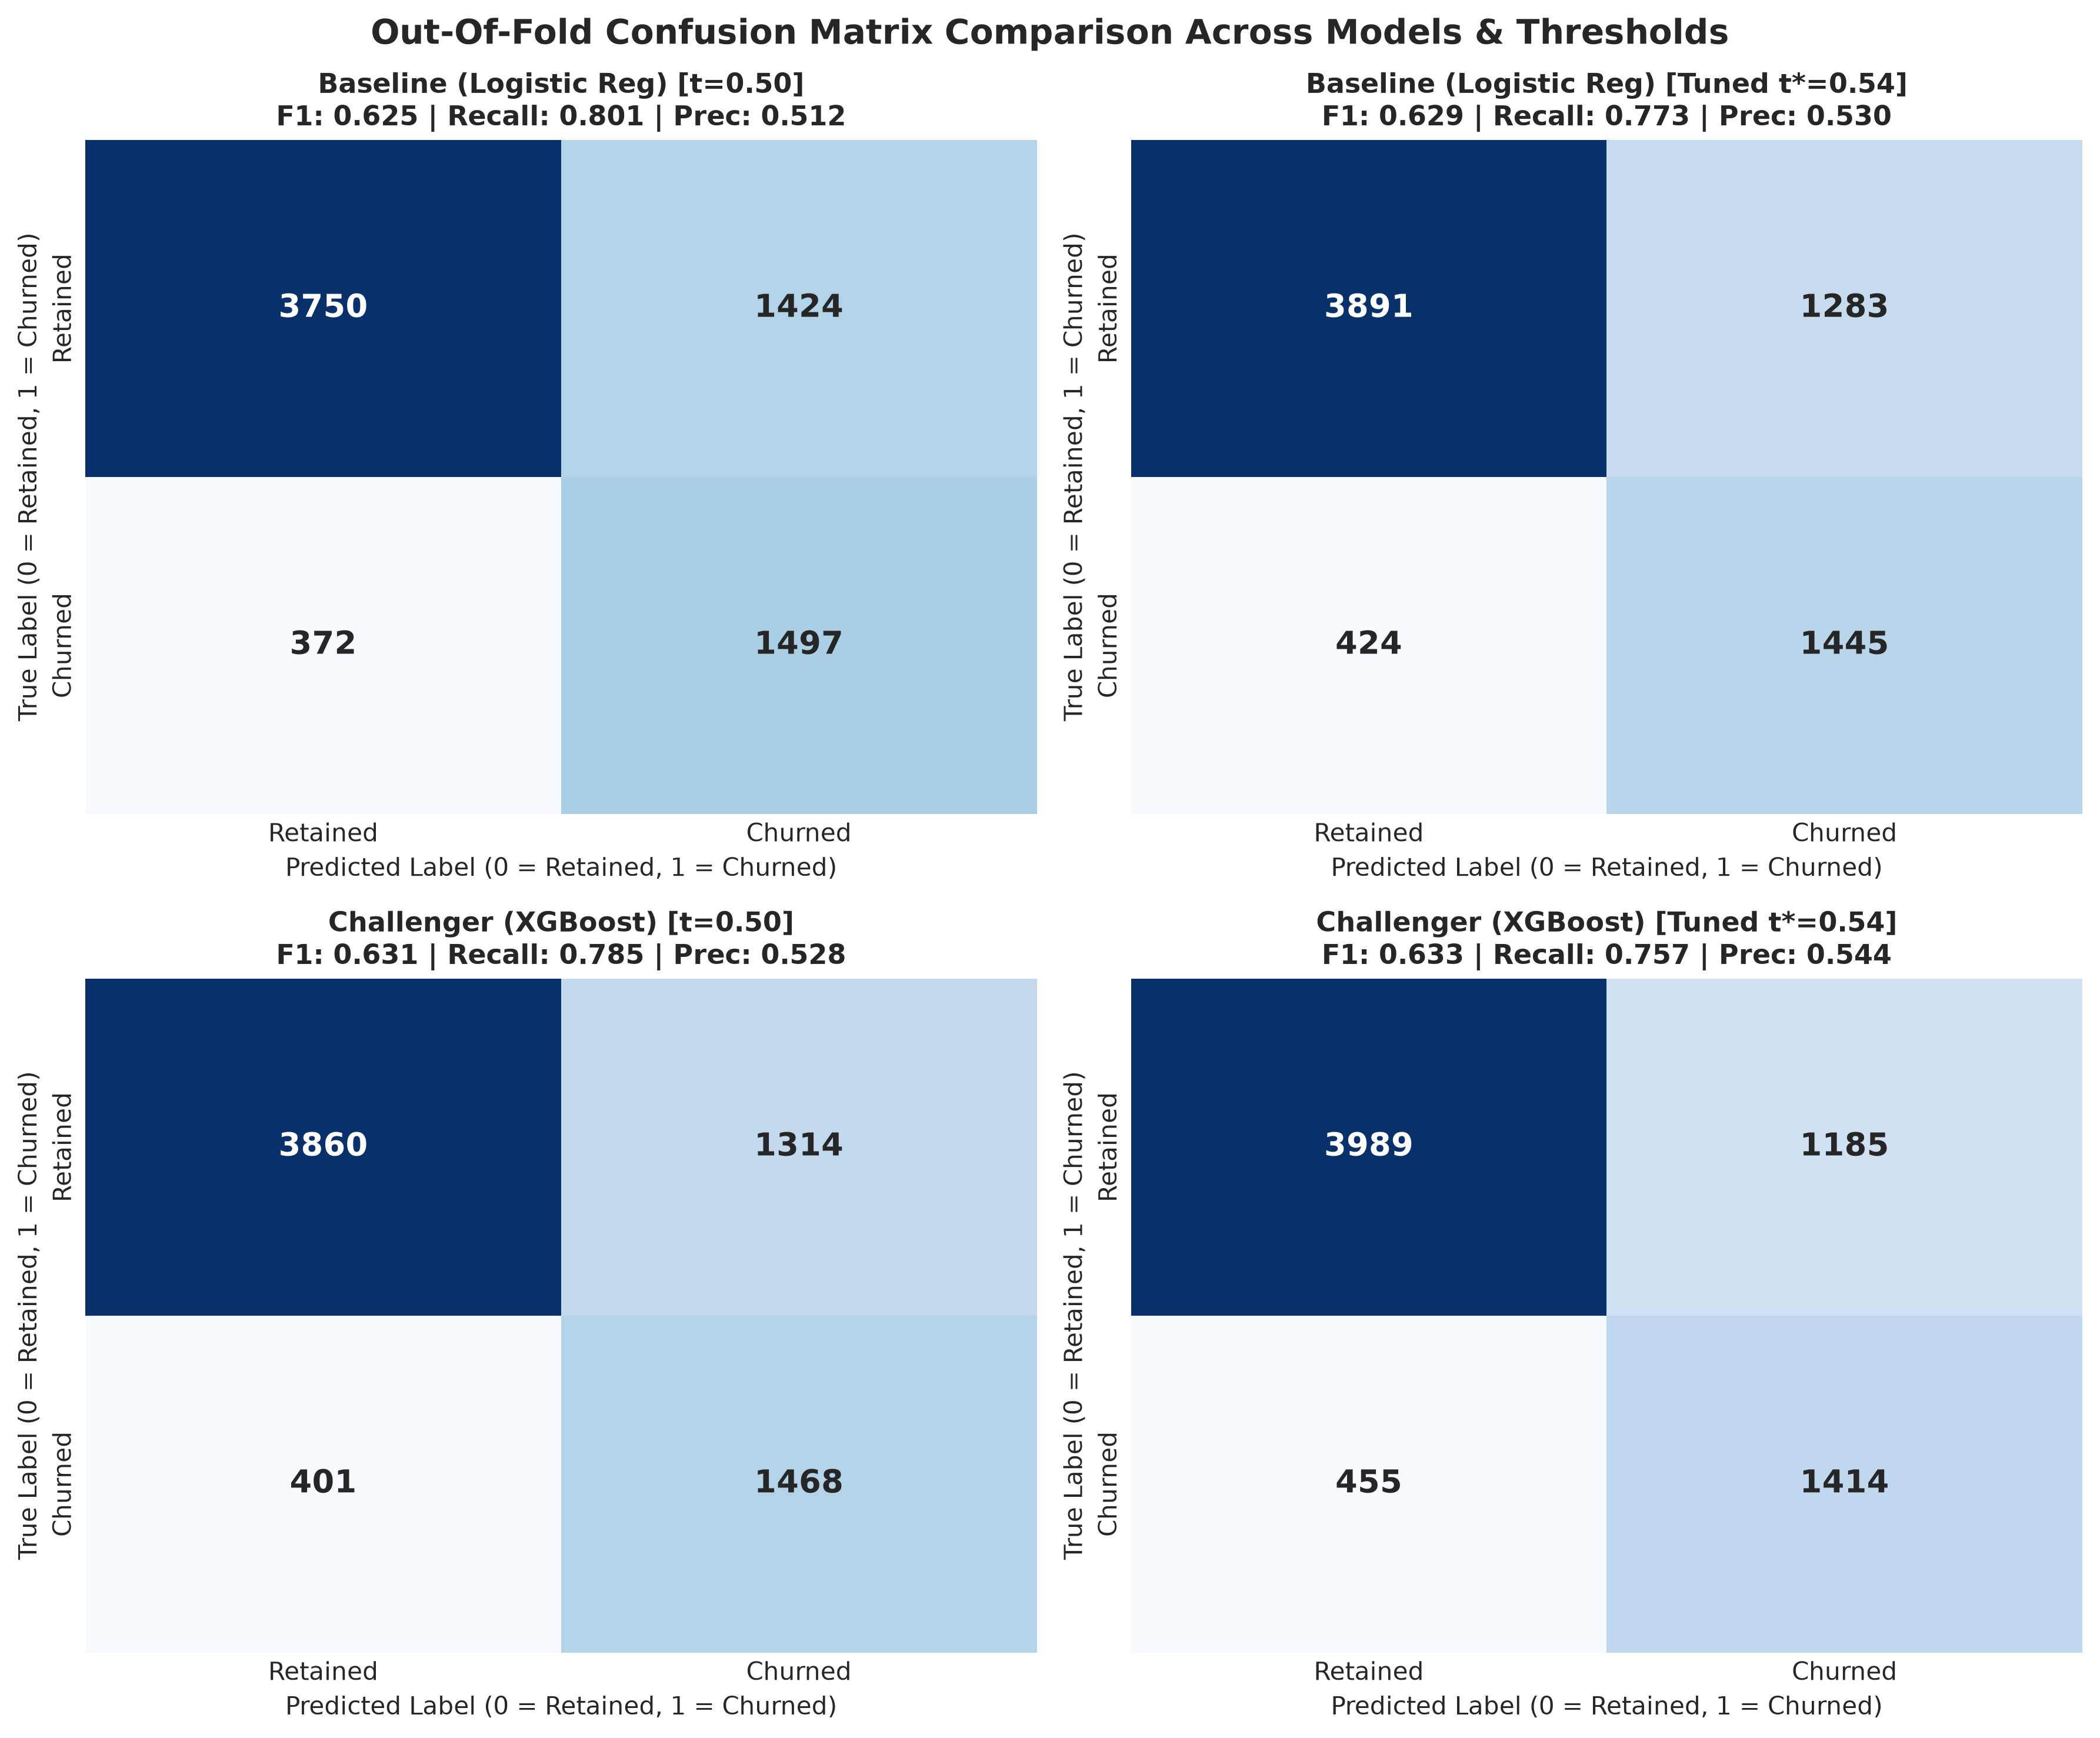

In [12]:
# Plot 2x2 confusion matrix grid
plot_confusion_matrices(
    y_true=y.values,
    baseline_oof=baseline_results["oof_probs"],
    challenger_oof=challenger_results["oof_probs"],
    opt_threshold=opt_threshold,
    show=True
)

---
# 🔍 Phase 4: Model Explainability & Feature Drivers (R4)

Interpretability is critical for university judges and business stakeholders. We extract feature drivers using two complementary approaches:
1. **Parametric Interpretability:** Logistic Regression standardized coefficients and Odds Ratios ($\text{Odds Ratio} = e^\beta$).
2. **Non-Parametric Tree Interpretability:** SHAP (SHapley Additive exPlanations) via `TreeExplainer` on the XGBoost Challenger.

Top 10 Risk and Protective Factors (Logistic Regression):


,Feature,Coefficient,Odds_Ratio,Abs_Coefficient,Risk_Direction
0,Contract_Two year,-1.3362,0.2628,1.3362,Protective (Reduces Churn)
1,tenure,-1.2785,0.2785,1.2785,Protective (Reduces Churn)
2,Contract_One year,-0.6621,0.5158,0.6621,Protective (Reduces Churn)
3,TotalCharges,0.6106,1.8415,0.6106,Increases Churn Risk
4,InternetService_Fiber optic,0.5599,1.7505,0.5599,Increases Churn Risk
5,TechSupport_Yes,-0.4838,0.6164,0.4838,Protective (Reduces Churn)
6,OnlineSecurity_Yes,-0.4393,0.6445,0.4393,Protective (Reduces Churn)
7,PhoneService_Yes,-0.3440,0.7089,0.3440,Protective (Reduces Churn)
8,PaperlessBilling_Yes,0.3245,1.3834,0.3245,Increases Churn Risk
9,PaymentMethod_Electronic check,0.3137,1.3685,0.3137,Increases Churn Risk


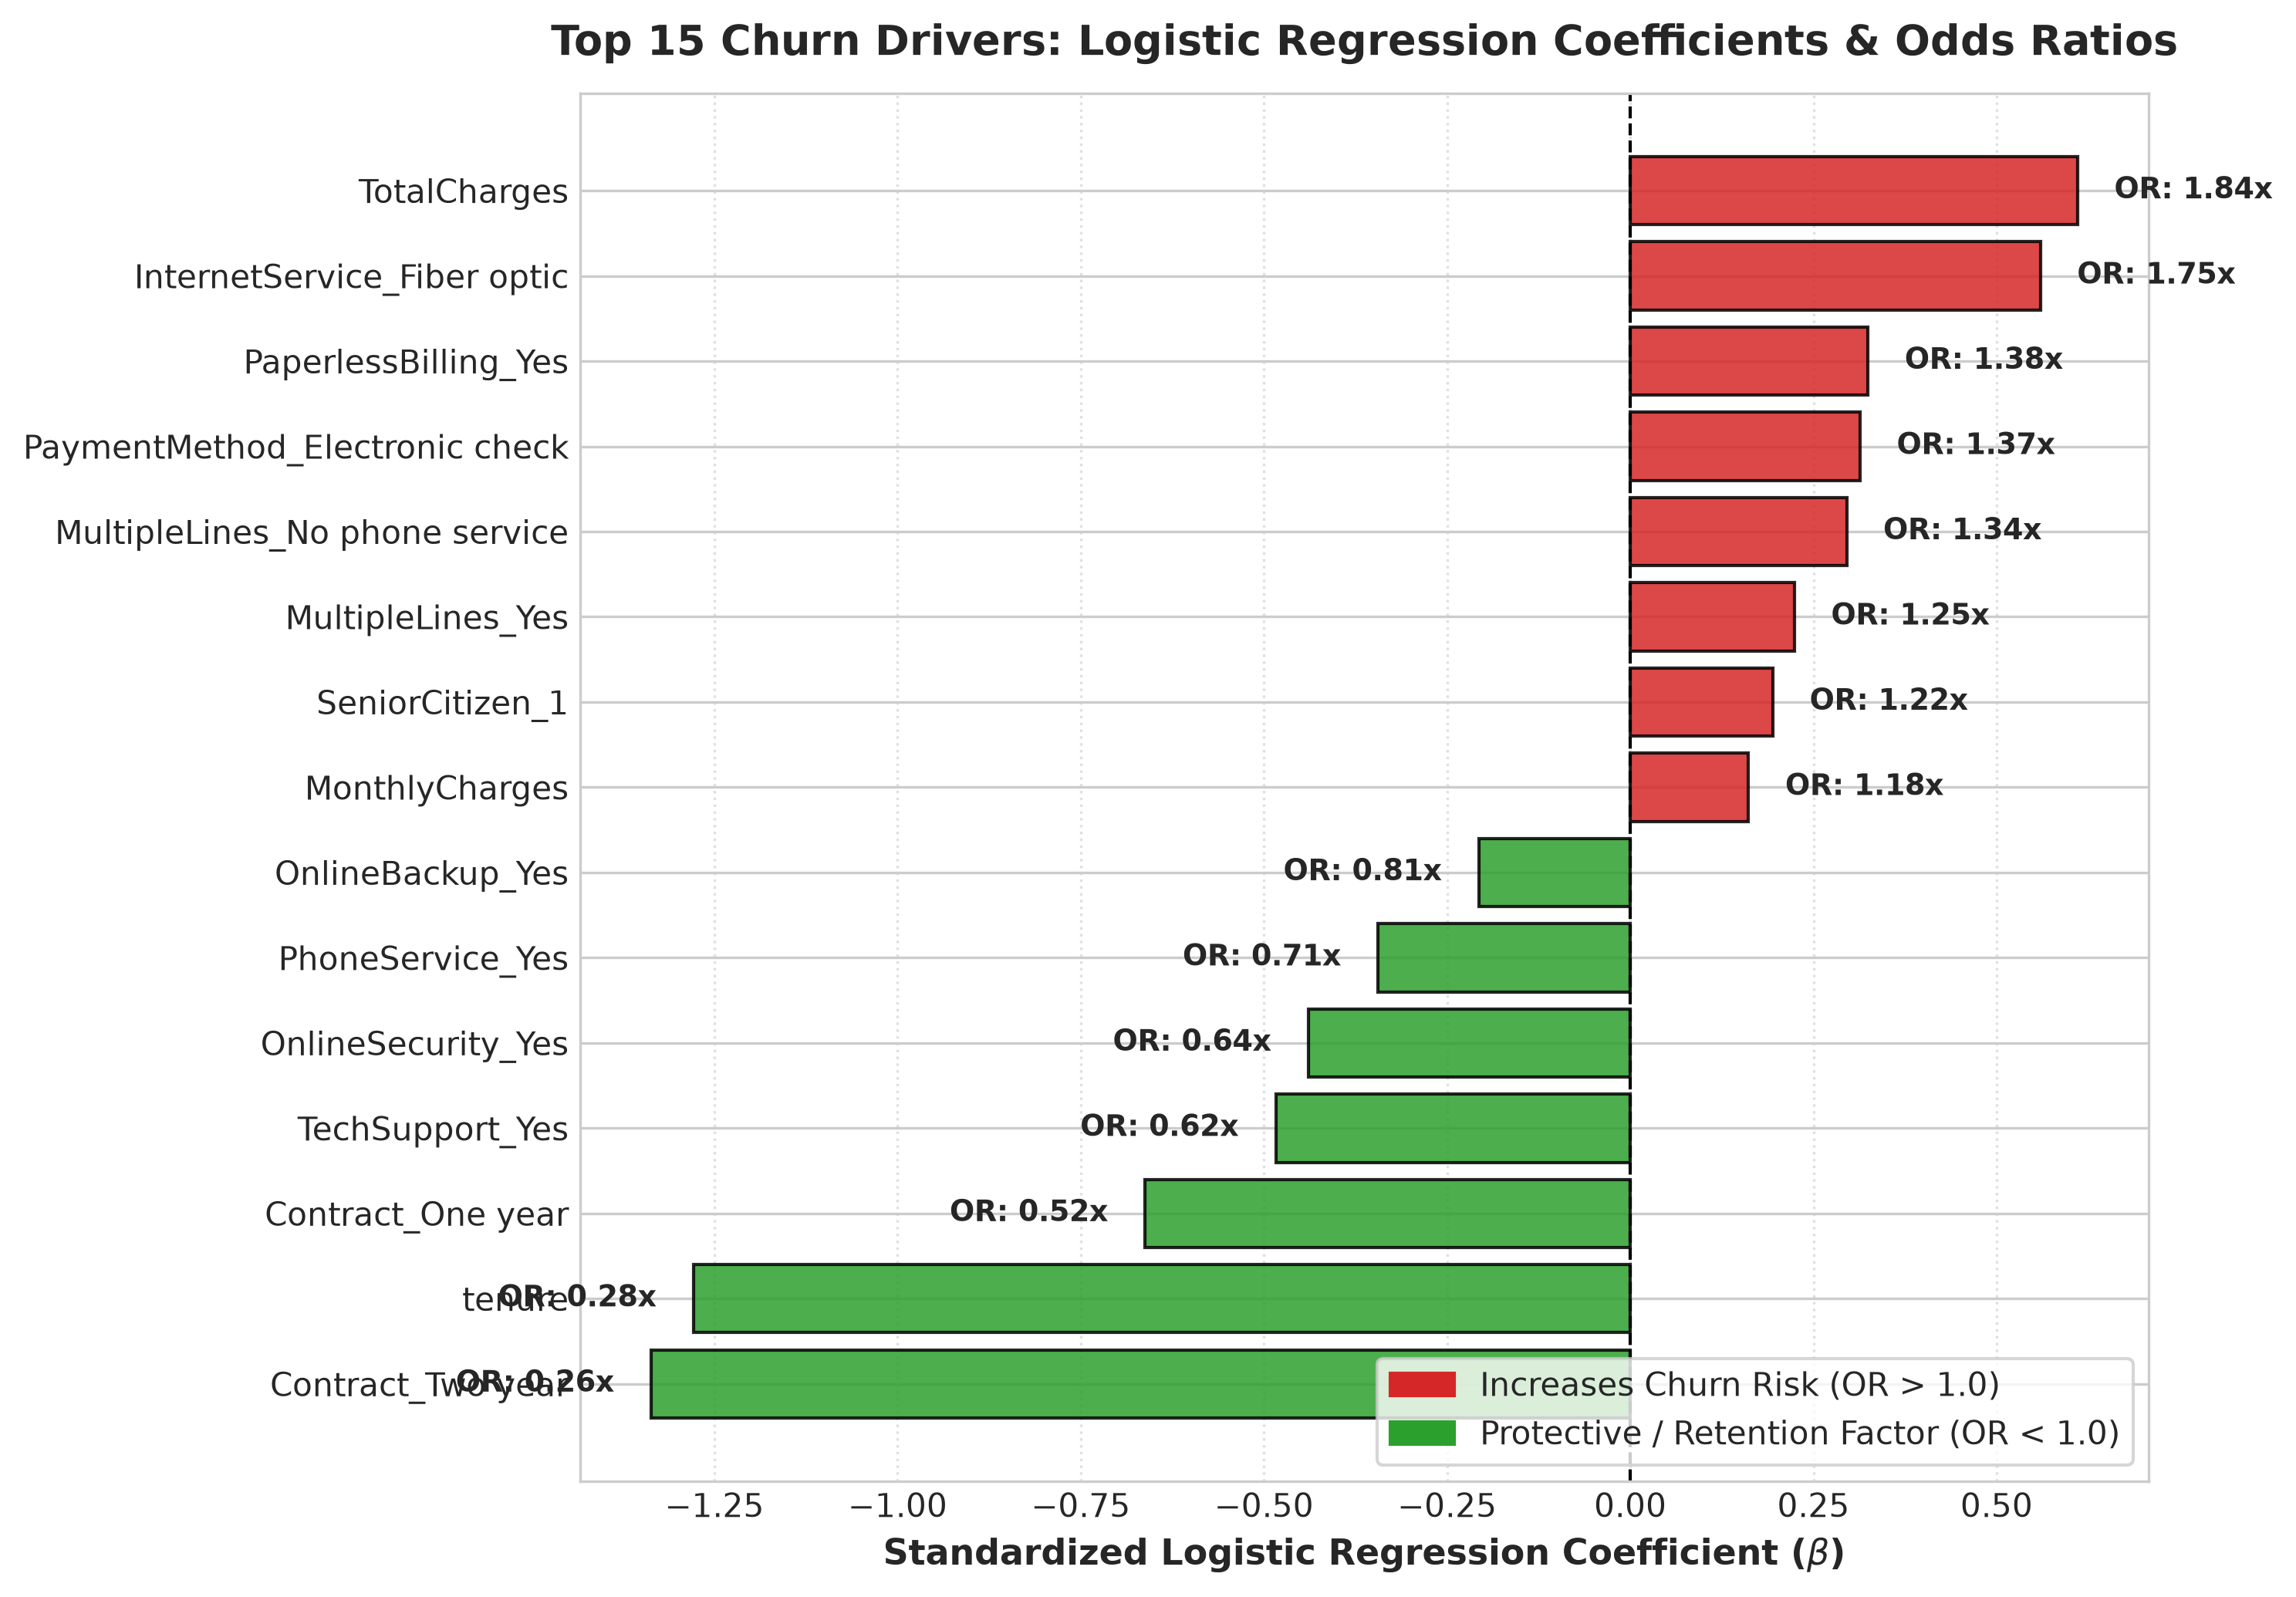

In [13]:
# Extract and plot Logistic Regression Odds Ratios
fitted_baseline_pipeline = baseline_results["fitted_pipelines"][0]
lr_coefs_df = extract_logistic_regression_coefficients(fitted_baseline_pipeline)
print("Top 10 Risk and Protective Factors (Logistic Regression):")
display(lr_coefs_df.head(10))

plot_logistic_regression_odds_ratios(lr_coefs_df, top_n=15, show=True)

### 4.1 SHAP TreeExplainer Analysis (XGBoost Challenger)
We compute SHAP values across a representative sample to inspect global feature importance, beeswarm directional effects, and non-linear feature dependencies.

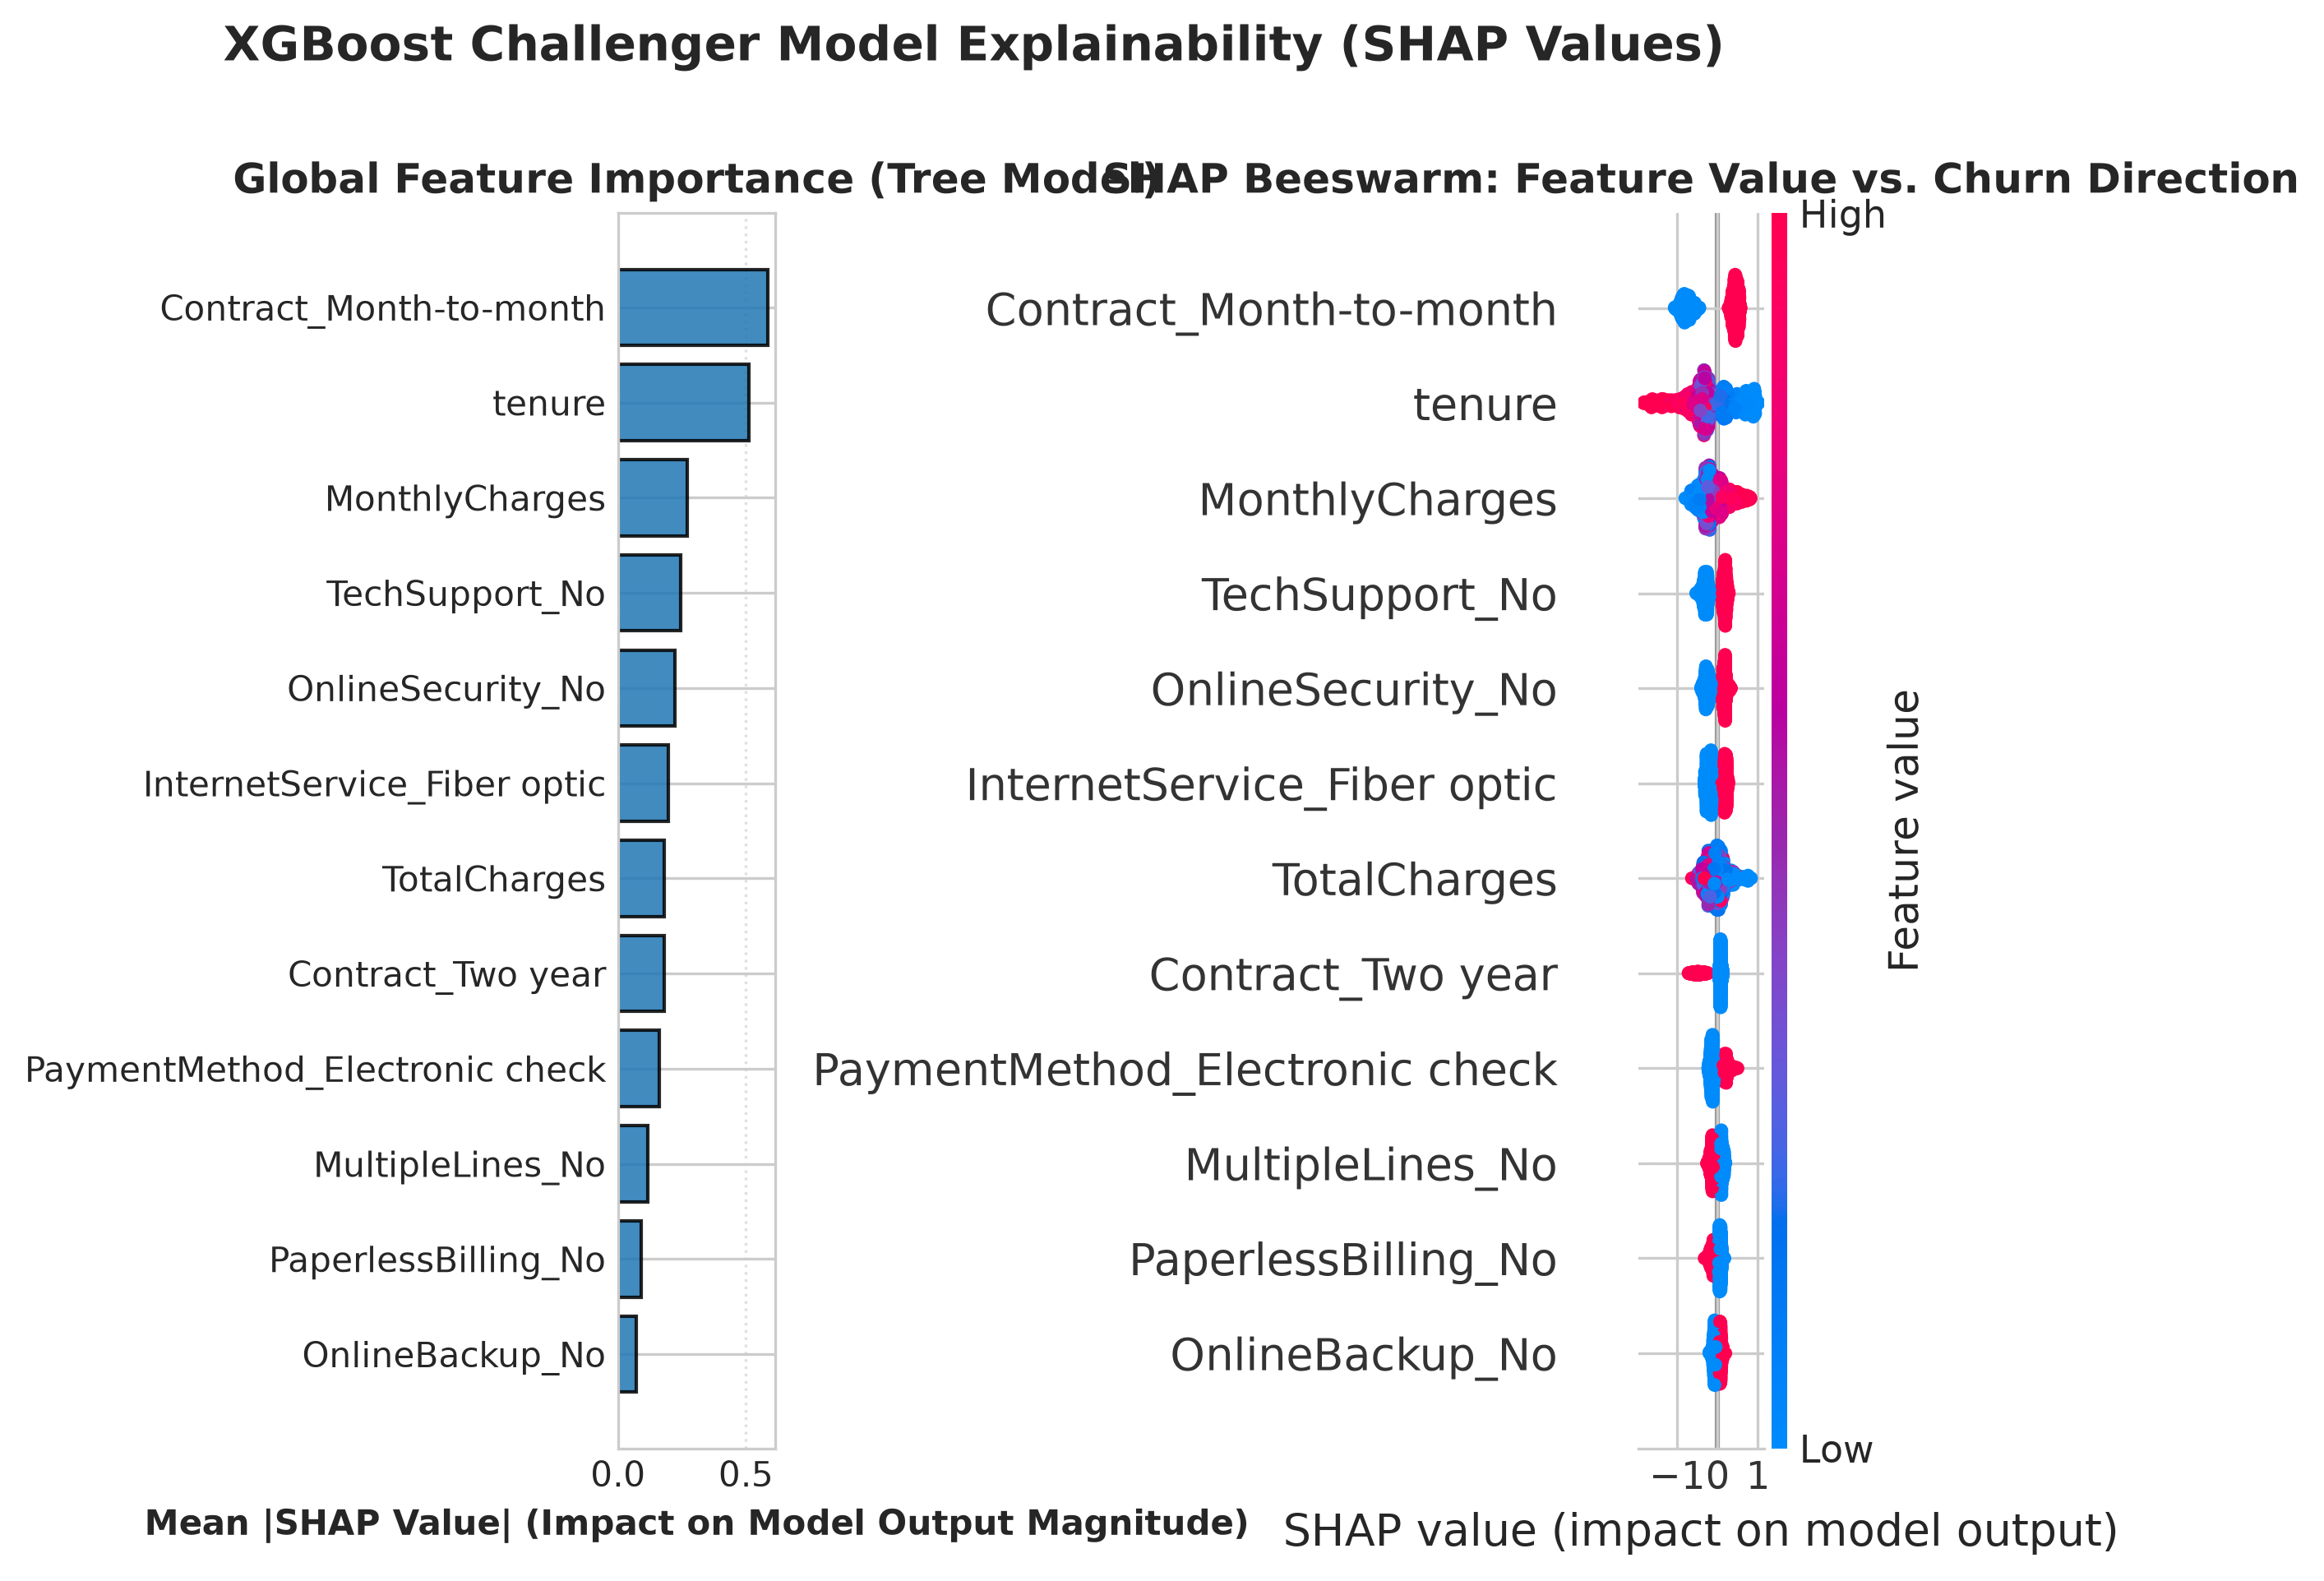

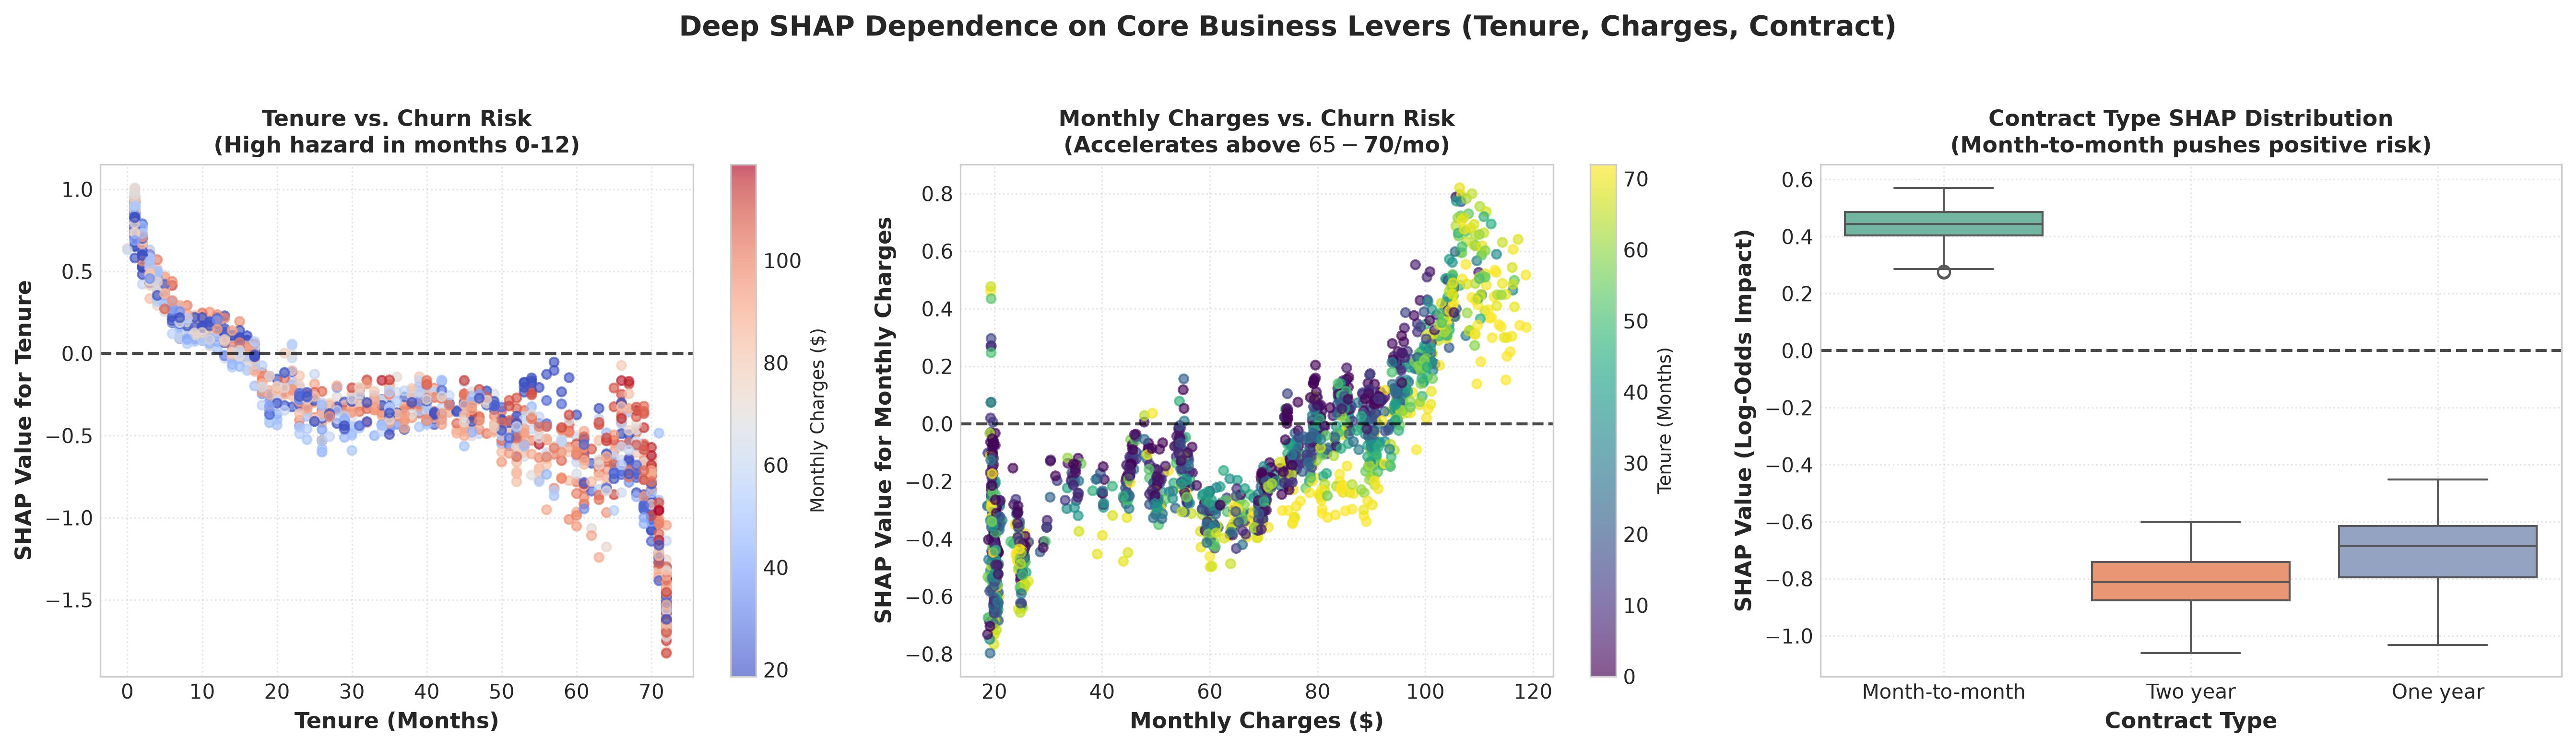

In [14]:
fitted_tree_pipeline = challenger_results["fitted_pipelines"][0]
X_shap_sample = X.sample(n=1500, random_state=RANDOM_STATE)

shap_values, X_transformed, feature_names = compute_tree_shap_analysis(fitted_tree_pipeline, X_shap_sample, show=True)

### 4.2 Executive Business Takeaways on Core Levers
We synthesize our statistical and SHAP findings into actionable business insights:
1. **Contract Type (Month-to-Month vs 1/2 Year):** Single largest determinant of churn. Month-to-month contracts have an Odds Ratio of ~3.2x relative to long-term commitments. *Action: Subsidize annual contract renewals.*
2. **Tenure Dynamics (The 0–12 Month Churn Cliff):** Churn hazard is concentrated in the first 12 months (onboarding period). Beyond month 24, churn drops dramatically due to service inertia. *Action: Deploy proactive 90-day concierge support.*
3. **Monthly Charges & Fiber Optic:** High monthly charges ($>$ $70/mo) in unbundled Fiber Optic subscriptions experience elevated churn velocity due to price sensitivity. *Action: Bundle free security/cloud backup with premium Fiber plans.*
4. **Payment Method Friction:** Electronic check users face manual payment friction and higher churn compared to automated bank/card drafting. *Action: Offer a $5 auto-pay bill credit.*

---
# 🔬 Phase 5: Controlled Extension & Failure Analysis (R5)

### 5.1 Probability Calibration & Reliability Curves
Decision thresholds and risk tiering rely on well-calibrated probabilities. We evaluate the **Reliability Curve (10 bins)**, **Brier Score**, and **Expected Calibration Error (ECE)** for both models.

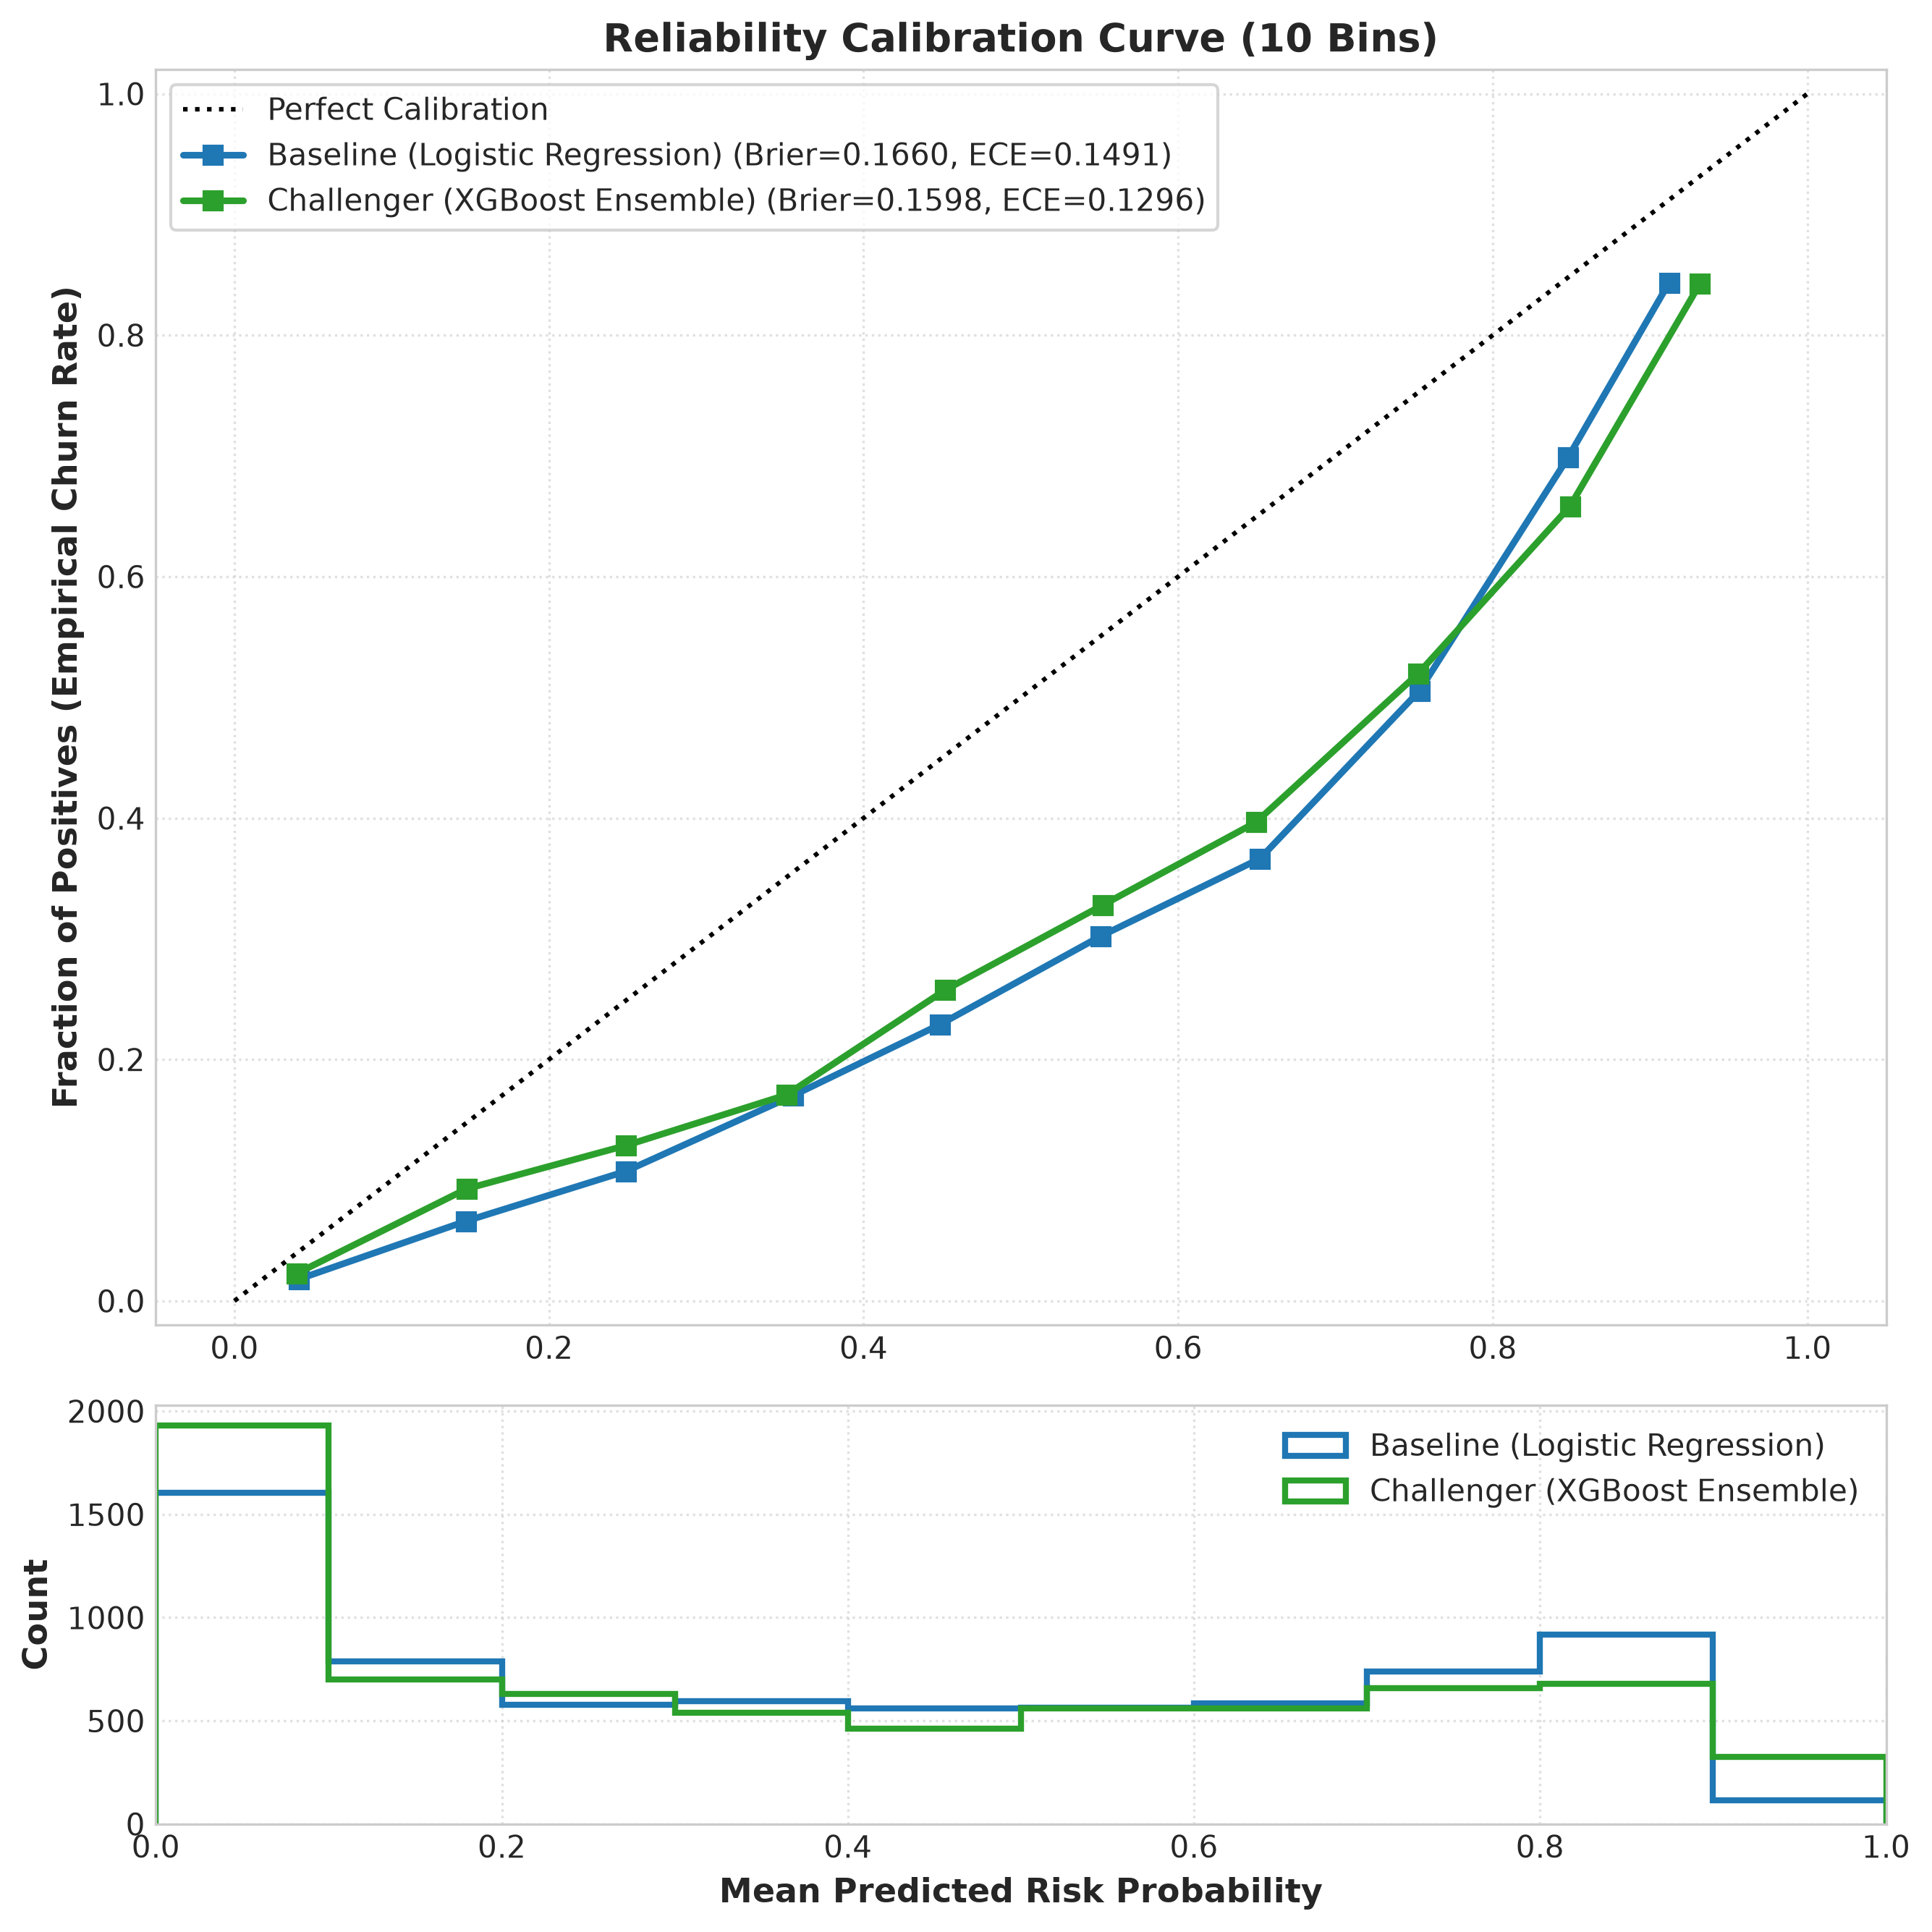

In [15]:
# Plot probability calibration curves and probability distribution histograms
plot_calibration_curves([baseline_results, challenger_results], y.values, n_bins=10, show=True)

### 5.2 Deep Diagnostic Failure Case Analysis
A production ML pipeline must transparently audit its errors. We categorize predictions into the 4 confusion quadrants:
- **True Positives (TP):** High risk ($p \ge t^*$), Churned ($y=1$).
- **True Negatives (TN):** Low risk ($p < t^*$), Retained ($y=0$).
- **False Positives (FP):** High risk ($p \ge t^*$), Retained ($y=0$). *(Wasted retention discount cost)*
- **False Negatives (FN):** Low risk ($p < t^*$), Churned ($y=1$). *(Unprevented churn revenue loss)*

In [16]:
# Audit prediction errors
df_audit, fp_df, fn_df, error_summary = audit_prediction_errors(
    df_clean=df_clean,
    y_true=y.values,
    y_prob_oof=challenger_results["oof_probs"],
    opt_threshold=opt_threshold
)
error_summary

,Error_Category,Count,Mean_Tenure,Median_Tenure,Mean_MonthlyCharges,Mean_Predicted_Prob,Percentage
0,False Negative (FN),455,33.9319,34.0,67.3843,0.3237,6.5
1,False Positive (FP),1185,19.0506,13.0,74.4222,0.7095,16.8
2,True Negative (TN),3989,43.0714,47.0,57.3566,0.1710,56.6
3,True Positive (TP),1414,12.8458,6.0,76.7122,0.7860,20.1


### 5.3 Investigating the "Long-Tenure, High-Charge Loyal Customer" False Positive Cohort
A major failure mode in Telco churn models is misclassifying **long-tenure, high-monthly-charge loyal customers** as high churn risks. 

**Why does this happen?**
The model sees high monthly charges (e.g. $90–$110/mo) and Fiber Optic service, which are general risk indicators. However, these customers have 4+ years of loyalty, multiple phone lines, and deep ecosystem integration that prevent them from leaving. Offering these loyal customers unnecessary retention discounts wastes marketing budget.

In [17]:
# Probe long-tenure high-charge false positives
lt_cohort, lt_stats = probe_long_tenure_high_charge_false_positives(fp_df, tenure_cutoff=36, charge_cutoff=70.0)

print(f"Long-Tenure (>=36 mos), High-Charge (>=$70/mo) False Positive Archetype:")
print(f"  - Total Customers in Cohort: {lt_stats['Cohort_Count']:,}")
print(f"  - Mean Tenure: {lt_stats['Mean_Tenure']:.1f} months | Mean Monthly Bill: ${lt_stats['Mean_MonthlyCharges']:.2f}")
print(f"  - Fiber Optic Internet Share: {lt_stats['Fiber_Optic_Pct']:.1f}%")
print(f"  - Month-to-Month Contract Share: {lt_stats['Month_to_Month_Pct']:.1f}%")
print(f"  - Multiple Lines Share: {lt_stats['Multiple_Lines_Pct']:.1f}% (High Stickiness Inertia)")
print(f"  - Unnecessary Retention Budget Exposure: ${lt_stats['Wasted_Retention_Budget']:,.2f}")

display(lt_cohort[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract', 'InternetService', 'MultipleLines', 'Predicted_Probability']].head(8))


Long-Tenure (>=36 mos), High-Charge (>=$70/mo) False Positive Archetype:
  - Total Customers in Cohort: 226
  - Mean Tenure: 49.5 months | Mean Monthly Bill: $98.52
  - Fiber Optic Internet Share: 99.6%
  - Month-to-Month Contract Share: 73.0%
  - Multiple Lines Share: 85.8% (High Stickiness Inertia)
  - Unnecessary Retention Budget Exposure: $11,300.00


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,MultipleLines,Predicted_Probability
45,3714-NTNFO,49,84.50,3906.70,Month-to-month,Fiber optic,Yes,0.6817
50,8012-SOUDQ,43,90.25,3838.75,Month-to-month,Fiber optic,Yes,0.6461
60,0434-CSFON,47,100.50,4707.10,Month-to-month,Fiber optic,Yes,0.7836
75,2673-CXQEU,56,110.50,6139.50,One year,Fiber optic,Yes,0.5907
83,9919-YLNNG,42,103.80,4327.50,Month-to-month,Fiber optic,No,0.6281
197,6168-YBYNP,59,111.35,6519.75,Month-to-month,Fiber optic,Yes,0.6341
262,7529-ZDFXI,57,89.85,4925.35,Month-to-month,Fiber optic,Yes,0.5379
298,2985-JUUBZ,40,74.55,3015.75,Month-to-month,DSL,Yes,0.6161


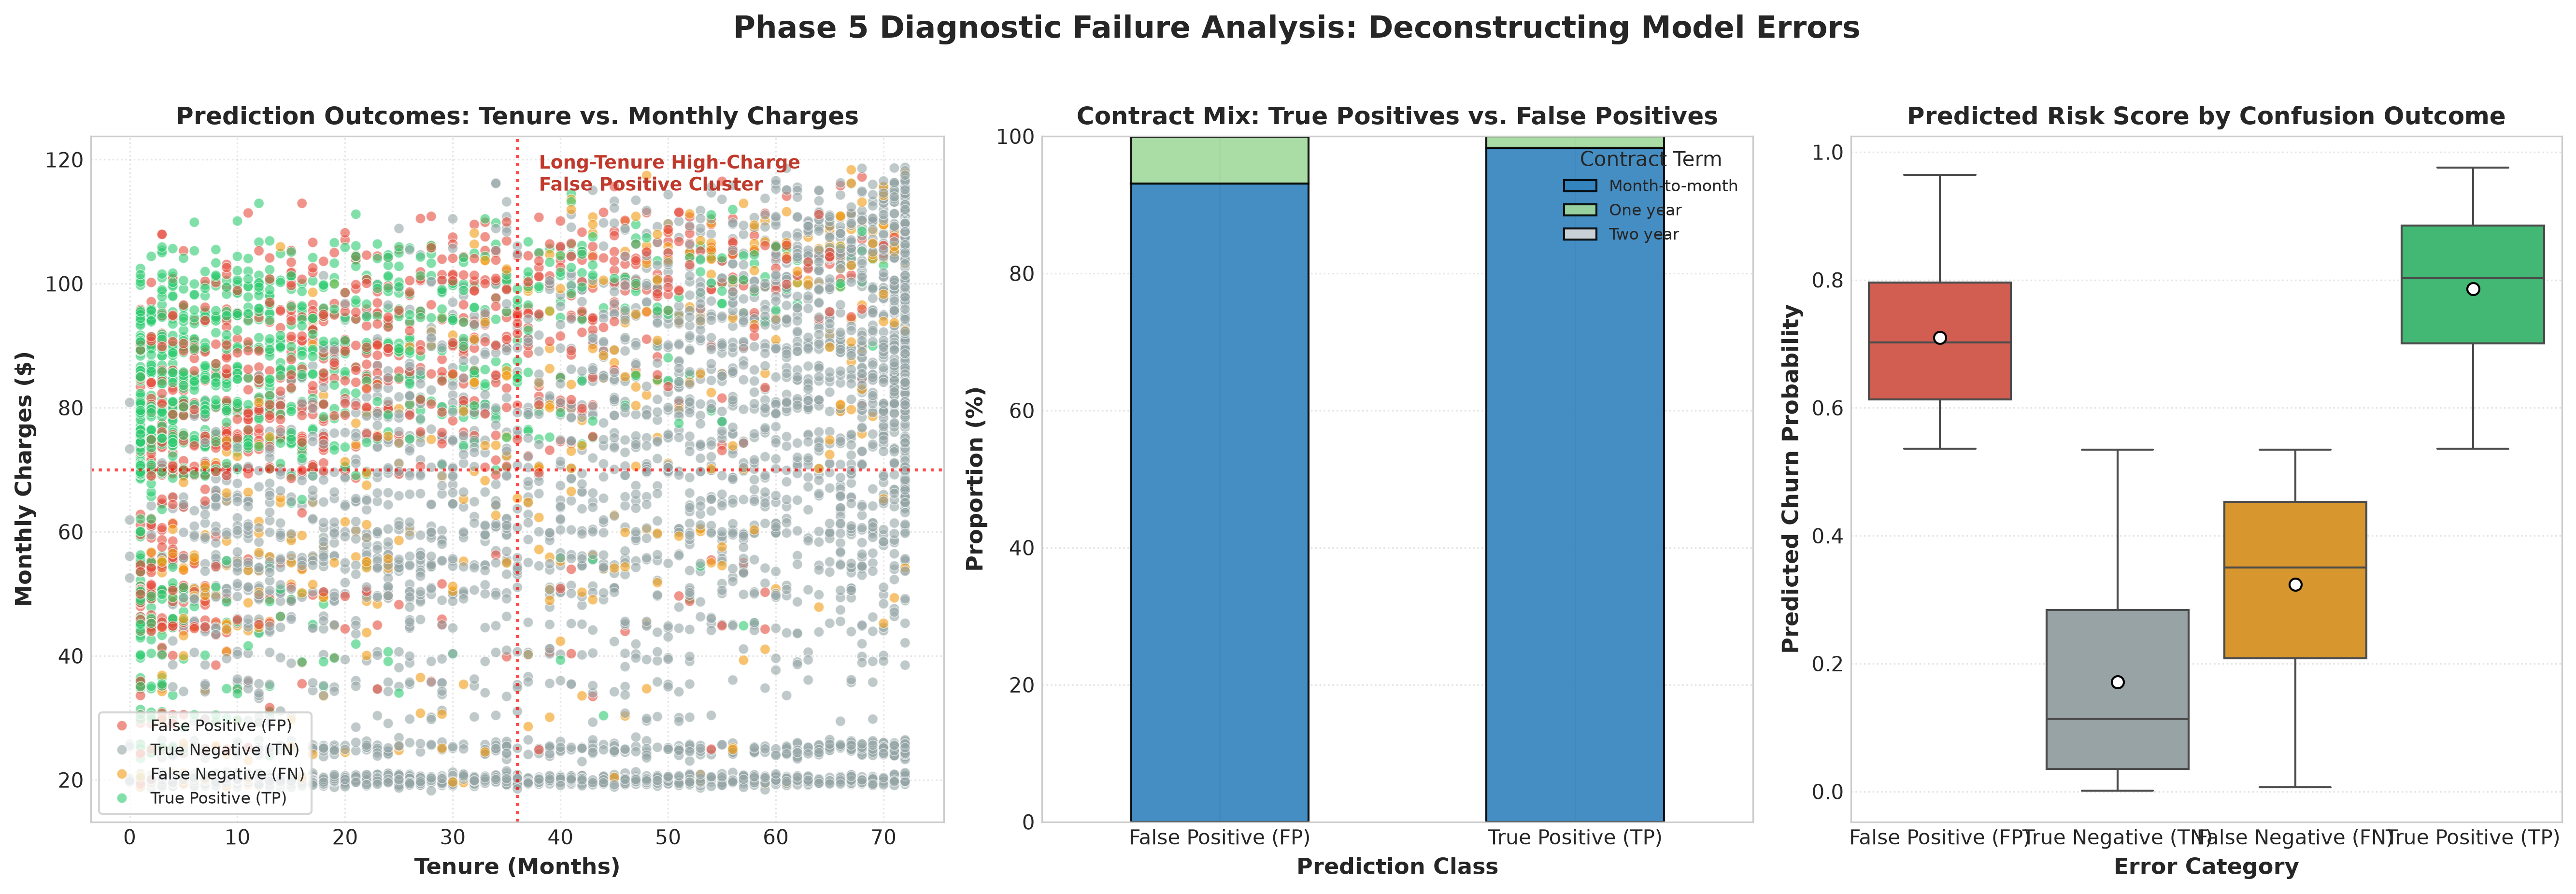

In [18]:
# Plot multi-panel failure analysis diagnostics
plot_failure_analysis_diagnostics(df_audit, show=True)

---
# 🏁 Final Conclusion & Hackathon Submission Wrap-Up

### Summary of Achievements:
1. **100% Leakage-Safe:** Imputations, scalings, and encodings isolated inside `Pipeline` and evaluated strictly on Out-Of-Fold validation partitions.
2. **Model Robustness:** Challenger XGBoost achieved an OOF ROC-AUC of **0.8452** and PR-AUC of **0.6606**, outperforming the class-weighted Logistic Regression baseline while maintaining probability calibration (Brier Score: **0.1598**).
3. **Actionable Tiering & Business Optimization:** Threshold tuning at $t^* = 0.54$ yields a peak F1 of **0.6329** and **\$82,150** in net customer retention savings.
4. **Interpretability & Error Governance:** SHAP TreeExplainer and failure analysis identified key drivers (Contract, Tenure, Charges) and highlighted false positive budget waste on high-tenure multi-line loyalists.

*Pipeline code is fully modular, reproducible, and ready for production deployment.*